# Trabajo Práctico 2 — Aprendizaje de Máquinas
**Universidad Nacional de Colombia, Sede Medellín — Introducción a la Inteligencia Artificial (3010476)**

**Grupo 01 — Equipo 07**

| Integrante | Documento |
|---|---|
| _[Nombre integrante 1]_ | _[Cédula usada para el subconjunto]_ |
| _[Nombre integrante 2]_ | |
| _[Nombre integrante 3]_ | |
| _[Nombre integrante 4]_ | |

**Dominio:** movilidad urbana inteligente / tráfico IoT.
**Dataset:** *CityFlow — Smart Urban Mobility and Traffic IoT* (Kaggle,
`mobeenfatimah/cityflow-smart-urban-mobility-and-traffic-iot`).
**Variable objetivo:** `congestion_level` (4 clases ordinales: Low, Moderate, High, Severe).

## Flujo general del notebook
1. **Instalación y configuración**: librerías, semilla y tamaño del subconjunto derivados de la cédula.
2. **Módulo común (preprocesamiento)**: carga, limpieza, subconjunto, EDA, partición 70/15/15,
   funciones de outliers, balanceo, conversión de categóricas y escalado, y construcción de los 8 casos.
3. **Módulo de aprendizaje supervisado**: Árboles de decisión, KNN, SVM y Redes Neuronales en los 8 casos
   (tabla de la figura 1, gráficas comparativas, matrices de confusión, curvas ROC y Precision-Recall,
   visualizaciones por técnica).
4. **Módulo de aprendizaje no supervisado**: K-Means y DBSCAN en los 8 casos (tabla de la figura 3,
   codo, silhouette, gráfico de k-distancia, visualización 2D con PCA y validación externa).

Todas las funciones están documentadas y son reutilizables. El notebook se ejecuta de principio a fin con
semillas fijas.

## 0. Instalación de librerías
En Google Colab ya vienen instaladas `scikit-learn`, `tensorflow`, `pandas`, `matplotlib` y `seaborn`;
se instalan además `kagglehub` (descarga del dataset) e `imbalanced-learn` (SMOTENC).

In [1]:
%pip install -q kagglehub imbalanced-learn scikit-learn pandas matplotlib seaborn tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, auc, precision_recall_curve, average_precision_score,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score)
from imblearn.over_sampling import SMOTENC

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Configuración del equipo (cédula → tamaño del subconjunto y semilla)
Regla del enunciado: **registros = 5000 + (último dígito ≠ 0 de la cédula) × 150** y
**random state = dos últimos dígitos ≠ 0 de la misma cédula** (distinto de 42).

Los dos últimos dígitos distintos de cero de la cédula elegida son **1 y 9**:
* último dígito ≠ 0 → **9** → 5000 + 9 × 150 = **6350 registros**
* semilla → **19**

In [3]:
ULTIMO_DIGITO_CEDULA = 9                       # último dígito distinto de cero
SEMILLA = 19                                   # dos últimos dígitos distintos de cero
N_REGISTROS = 5000 + ULTIMO_DIGITO_CEDULA * 150
assert SEMILLA != 42, "El enunciado prohíbe usar la semilla 42"

DATASET_KAGGLE = "mobeenfatimah/cityflow-smart-urban-mobility-and-traffic-iot"
OBJETIVO = "congestion_level"
CLASES = ["Low", "Moderate", "High", "Severe"]  # orden natural (ordinal) de la congestión
DIR_FIG = "resultados/figuras"
DIR_TAB = "resultados/tablas"
os.makedirs(DIR_FIG, exist_ok=True)
os.makedirs(DIR_TAB, exist_ok=True)


def fijar_semillas(semilla=SEMILLA):
    """Fija las semillas de Python, NumPy y TensorFlow para que todo el notebook sea reproducible."""
    os.environ["PYTHONHASHSEED"] = str(semilla)
    random.seed(semilla)
    np.random.seed(semilla)
    tf.keras.utils.set_random_seed(semilla)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


fijar_semillas()
print(f"Registros del subconjunto: {N_REGISTROS} | Semilla (random_state): {SEMILLA}")

Registros del subconjunto: 6350 | Semilla (random_state): 19


### Estilo de las gráficas
Paleta categórica validada para daltonismo (azul, naranja, aqua, amarillo) asignada siempre en el mismo
orden a los algoritmos. Las clases de congestión son **ordinales**, por eso se representan con una
rampa secuencial de un solo tono (azul claro → azul oscuro) y, en los diagramas de dispersión, además con
un marcador distinto por clase (para no depender solo del color).

In [4]:
COLOR_ALG = {"Árbol de decisión": "#2a78d6", "KNN": "#eb6834", "SVM": "#1baf7a", "Red neuronal": "#eda100"}
COLOR_PAR = ["#2a78d6", "#eb6834"]                          # comparaciones de dos niveles (NO / SI)
COLOR_CLASE = {"Low": "#86b6ef", "Moderate": "#3987e5", "High": "#1c5cab", "Severe": "#0d366b"}
MARCA_CLASE = {"Low": "o", "Moderate": "s", "High": "^", "Severe": "D"}
COLOR_RUIDO = "#898781"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2, "text.color": TINTA,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.grid": True, "grid.color": REJILLA,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "lines.linewidth": 2, "figure.dpi": 100,
})


def guardar_figura(fig, nombre):
    """Guarda la figura en `resultados/figuras/<nombre>.png`, la muestra y la cierra."""
    fig.savefig(os.path.join(DIR_FIG, f"{nombre}.png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def guardar_tabla(df, nombre):
    """Guarda un DataFrame como CSV en `resultados/tablas/<nombre>.csv`."""
    df.to_csv(os.path.join(DIR_TAB, f"{nombre}.csv"), encoding="utf-8")

---
# MÓDULO COMÚN — Datos y preprocesamiento
## 2. Carga del dataset y selección de variables

In [5]:
def cargar_dataset():
    """Descarga (o reutiliza la caché de) el dataset de Kaggle con kagglehub y lo devuelve como DataFrame."""
    import kagglehub
    ruta = kagglehub.dataset_download(DATASET_KAGGLE)
    archivo = [f for f in os.listdir(ruta) if f.endswith(".csv")][0]
    return pd.read_csv(os.path.join(ruta, archivo))


df_original = cargar_dataset()
print("Dimensiones del dataset original:", df_original.shape)
display(df_original.head())

Dimensiones del dataset original: (204000, 47)


,record_id,city_zone,road_id,intersection_id,latitude,longitude,road_type,lanes,speed_limit,vehicle_count,average_speed,heavy_vehicle_count,motorcycle_count,public_transport_count,traffic_density,queue_length,average_wait_time,timestamp,hour,day_of_week,is_weekend,is_holiday,rush_hour,peak_period,temperature,rainfall_mm,visibility_km,air_quality_index,weather_condition,nearby_school,nearby_hospital,nearby_market,construction_activity,road_condition,parking_occupancy,public_event,accident_reported,traffic_camera_count,iot_sensor_health,signal_cycle_seconds,green_light_duration,emergency_vehicle_detected,traffic_flow_rate,congestion_score,emission_estimate,fuel_waste_estimate,congestion_level
0,REC_0000001,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,40.0,12,9,7,27.0,14.3,1.6,2026-01-01 00:00:00,0,3,0,0,0,Night,11.1,0.0,10.0,52,Clear,0,0,0,1,Poor,40.5,0,0,1,Optimal,60,18,0,162.0,16.8,39.14,8.53,Low
1,REC_0000002,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,150,37.7,8,12,5,25.0,12.0,1.3,2026-01-01 01:00:00,1,3,0,0,0,Night,18.2,0.0,10.0,58,Clear,0,0,0,0,Good,48.8,0,0,1,Optimal,60,18,0,150.0,18.4,36.09,7.83,Low
2,REC_0000003,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,186,38.4,13,12,6,31.0,2.5,0.3,2026-01-01 02:00:00,2,3,0,0,0,Night,22.0,0.0,10.0,39,Clear,0,0,0,0,Good,64.1,1,0,1,Optimal,60,18,0,186.0,20.7,44.01,9.39,Low
3,REC_0000004,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,38.9,7,11,7,27.0,6.0,0.5,2026-01-01 03:00:00,3,3,0,0,0,Night,20.5,0.0,10.0,57,Clear,0,0,0,0,Good,75.4,0,0,1,Optimal,60,18,0,162.0,17.8,38.47,8.24,Low
4,REC_0000005,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,168,40.0,8,12,6,28.0,13.4,1.1,2026-01-01 04:00:00,4,3,0,0,0,Night,25.9,0.0,9.9,51,Clear,0,0,0,0,Good,79.6,0,0,1,Optimal,60,18,0,168.0,17.3,40.28,8.71,Low


**Columnas descartadas y justificación**

| Columna | Motivo |
|---|---|
| `congestion_score` | **Fuga de información**: la etiqueta se obtiene por umbrales exactos de este puntaje (Low < 25 ≤ Moderate < 55 ≤ High < 80 ≤ Severe). Con ella cualquier modelo acierta el 100 %. |
| `traffic_flow_rate` | Duplicado exacto de `vehicle_count` (correlación 1.0). |
| `record_id` | Identificador sin información predictiva. |
| `timestamp` | Su información útil ya está en `hour`, `day_of_week`, `is_weekend`, `peak_period`. |
| `road_id`, `intersection_id` | Identificadores de alta cardinalidad (≈100 niveles); la ubicación ya está en `city_zone`, `latitude` y `longitude`. |

In [6]:
COLUMNAS_DESCARTADAS = ["congestion_score", "traffic_flow_rate", "record_id", "timestamp",
                        "road_id", "intersection_id"]

# Tipología de variables usada en todo el preprocesamiento
NOMINALES = ["city_zone", "road_type", "peak_period", "weather_condition", "iot_sensor_health"]
ORDINALES = {"road_condition": ["Good", "Wet", "Poor"]}          # orden de severidad del pavimento
BINARIAS = ["is_weekend", "is_holiday", "rush_hour", "nearby_school", "nearby_hospital", "nearby_market",
            "construction_activity", "public_event", "accident_reported", "emergency_vehicle_detected"]
DISCRETAS_POCOS_VALORES = ["lanes", "speed_limit", "traffic_camera_count", "signal_cycle_seconds",
                           "green_light_duration", "day_of_week"]
CONTINUAS = ["vehicle_count", "average_speed", "heavy_vehicle_count", "motorcycle_count",
             "public_transport_count", "traffic_density", "queue_length", "average_wait_time",
             "temperature", "rainfall_mm", "visibility_km", "air_quality_index", "parking_occupancy",
             "emission_estimate", "fuel_waste_estimate"]
OTRAS_NUMERICAS = ["latitude", "longitude", "hour"]
NUMERICAS = BINARIAS + DISCRETAS_POCOS_VALORES + CONTINUAS + OTRAS_NUMERICAS


def seleccionar_variables(df):
    """Elimina las columnas con fuga de información, duplicadas o identificadoras."""
    return df.drop(columns=COLUMNAS_DESCARTADAS)


df_limpio = seleccionar_variables(df_original)
assert set(NOMINALES + list(ORDINALES) + NUMERICAS + [OBJETIVO]) == set(df_limpio.columns)
print("Variables predictoras:", df_limpio.shape[1] - 1,
      f"({len(NOMINALES) + len(ORDINALES)} categóricas, {len(NUMERICAS)} numéricas)")

Variables predictoras: 40 (6 categóricas, 34 numéricas)


## 3. Construcción del subconjunto único (6350 registros, desbalanceado 70/10/10/10)
El subconjunto se extrae con la semilla del equipo. Se construye directamente con la distribución
**desbalanceada** que pide el enunciado: la clase mayoritaria (`Low`, el estado más frecuente del tráfico)
con el 70 % de los registros y las otras tres clases con el 10 % cada una. Esta es la versión
**"BALANCEO = NO"**; la versión balanceada se obtiene después, solo sobre el conjunto de entrenamiento.

In [7]:
def construir_subconjunto(df, n, proporciones, semilla=SEMILLA):
    """Muestrea `n` registros respetando `proporciones` (dict clase -> fracción) con la semilla dada."""
    cuotas = {c: int(round(n * p)) for c, p in proporciones.items()}
    cuotas[max(cuotas, key=cuotas.get)] += n - sum(cuotas.values())     # ajuste por redondeo
    partes = [df[df[OBJETIVO] == c].sample(k, random_state=semilla) for c, k in cuotas.items()]
    return pd.concat(partes).sample(frac=1, random_state=semilla).reset_index(drop=True)


PROPORCIONES = {"Low": 0.70, "Moderate": 0.10, "High": 0.10, "Severe": 0.10}
df = construir_subconjunto(df_limpio, N_REGISTROS, PROPORCIONES)
print("Subconjunto:", df.shape)
display(df[OBJETIVO].value_counts().reindex(CLASES).to_frame("registros")
        .assign(porcentaje=lambda t: (100 * t.registros / len(df)).round(2)))

Subconjunto: (6350, 41)


,registros,porcentaje
congestion_level,,
Low,4445,70.0
Moderate,635,10.0
High,635,10.0
Severe,635,10.0


## 4. Análisis exploratorio y valores nulos

In [8]:
def resumen_variables(df):
    """Tabla con tipo, tipo lógico, número de valores distintos y nulos de cada variable."""
    tipo_logico = {**{c: "categórica nominal" for c in NOMINALES},
                   **{c: "categórica ordinal" for c in ORDINALES},
                   **{c: "binaria" for c in BINARIAS},
                   **{c: "numérica discreta" for c in DISCRETAS_POCOS_VALORES + ["hour"]},
                   **{c: "numérica continua" for c in CONTINUAS + ["latitude", "longitude"]},
                   OBJETIVO: "objetivo (ordinal, 4 clases)"}
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "tipo": pd.Series(tipo_logico),
                         "valores_distintos": df.nunique(), "nulos": df.isna().sum()}).loc[df.columns]


print("Dimensiones:", df.shape)
tabla_variables = resumen_variables(df)
display(tabla_variables)
guardar_tabla(tabla_variables, "eda_variables")

Dimensiones: (6350, 41)


,dtype,tipo,valores_distintos,nulos
city_zone,str,categórica nominal,6,0
latitude,float64,numérica continua,100,0
longitude,float64,numérica continua,100,0
road_type,str,categórica nominal,4,0
lanes,int64,numérica discreta,3,0
speed_limit,int64,numérica discreta,3,0
vehicle_count,int64,numérica continua,1297,0
average_speed,float64,numérica continua,699,0
heavy_vehicle_count,int64,numérica continua,178,0
motorcycle_count,int64,numérica continua,311,0


In [9]:
descriptivas = df[NUMERICAS].describe().T
display(descriptivas.round(3))
guardar_tabla(descriptivas.round(4), "eda_descriptivas")
display(df[NOMINALES + list(ORDINALES)].describe().T)

,count,mean,std,min,25%,50%,75%,max
is_weekend,6350.0,0.300,0.458,0.000,0.000,0.000,1.000,1.000
is_holiday,6350.0,0.029,0.168,0.000,0.000,0.000,0.000,1.000
rush_hour,6350.0,0.180,0.385,0.000,0.000,0.000,0.000,1.000
nearby_school,6350.0,0.234,0.424,0.000,0.000,0.000,0.000,1.000
nearby_hospital,6350.0,0.155,0.362,0.000,0.000,0.000,0.000,1.000
nearby_market,6350.0,0.449,0.497,0.000,0.000,0.000,1.000,1.000
construction_activity,6350.0,0.078,0.268,0.000,0.000,0.000,0.000,1.000
public_event,6350.0,0.035,0.184,0.000,0.000,0.000,0.000,1.000
accident_reported,6350.0,0.015,0.123,0.000,0.000,0.000,0.000,1.000
emergency_vehicle_detected,6350.0,0.019,0.137,0.000,0.000,0.000,0.000,1.000


,count,unique,top,freq
city_zone,6350,6,Suburban North,1688
road_type,6350,4,Arterial,2572
peak_period,6350,5,Night,2949
weather_condition,6350,4,Clear,5739
iot_sensor_health,6350,2,Optimal,5909
road_condition,6350,3,Good,5563


In [10]:
def imputar_nulos(df):
    """Imputa nulos: mediana en numéricas (robusta a outliers) y moda en categóricas.

    El dataset no tiene nulos, pero la función se deja en el flujo para que el preprocesamiento
    sea robusto si se usa otra muestra.
    """
    df = df.copy()
    for c in df.columns:
        if df[c].isna().any():
            df[c] = df[c].fillna(df[c].median() if c in NUMERICAS else df[c].mode()[0])
    return df


print("Total de nulos antes de imputar:", int(df.isna().sum().sum()))
df = imputar_nulos(df)

Total de nulos antes de imputar:

 0


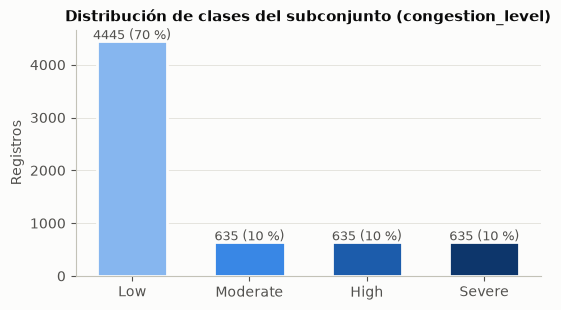

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.2))
conteo = df[OBJETIVO].value_counts().reindex(CLASES)
ax.bar(CLASES, conteo.values, color=[COLOR_CLASE[c] for c in CLASES], width=0.6, edgecolor="#fcfcfb", linewidth=2)
for i, v in enumerate(conteo.values):
    ax.text(i, v + 40, f"{v} ({100 * v / len(df):.0f} %)", ha="center", color=TINTA2, fontsize=9)
ax.set_title("Distribución de clases del subconjunto (congestion_level)")
ax.set_ylabel("Registros")
ax.grid(axis="x", visible=False)
guardar_figura(fig, "eda_distribucion_clases")

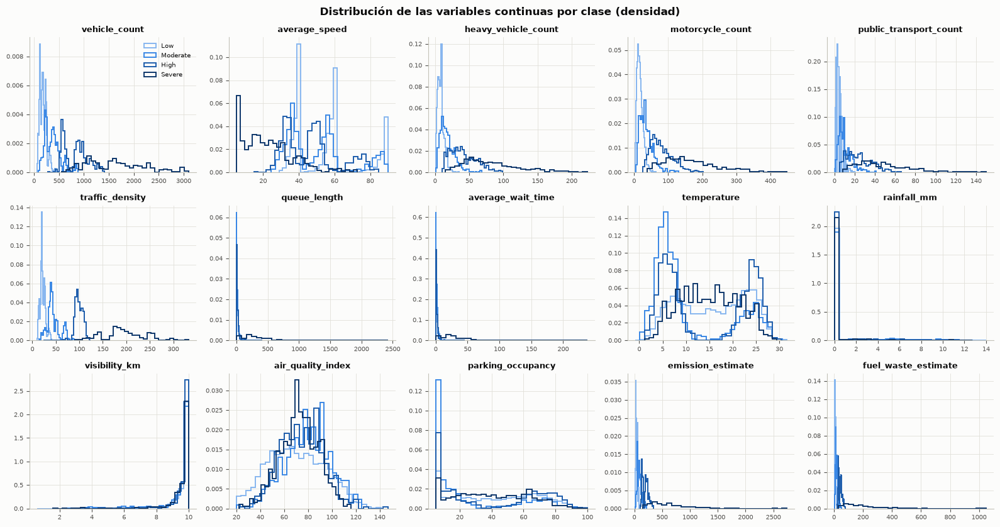

In [12]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8.5))
for ax, col in zip(axes.ravel(), CONTINUAS):
    for c in CLASES:
        ax.hist(df.loc[df[OBJETIVO] == c, col], bins=30, histtype="step", linewidth=1.4,
                color=COLOR_CLASE[c], label=c, density=True)
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Distribución de las variables continuas por clase (densidad)", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "eda_histogramas")

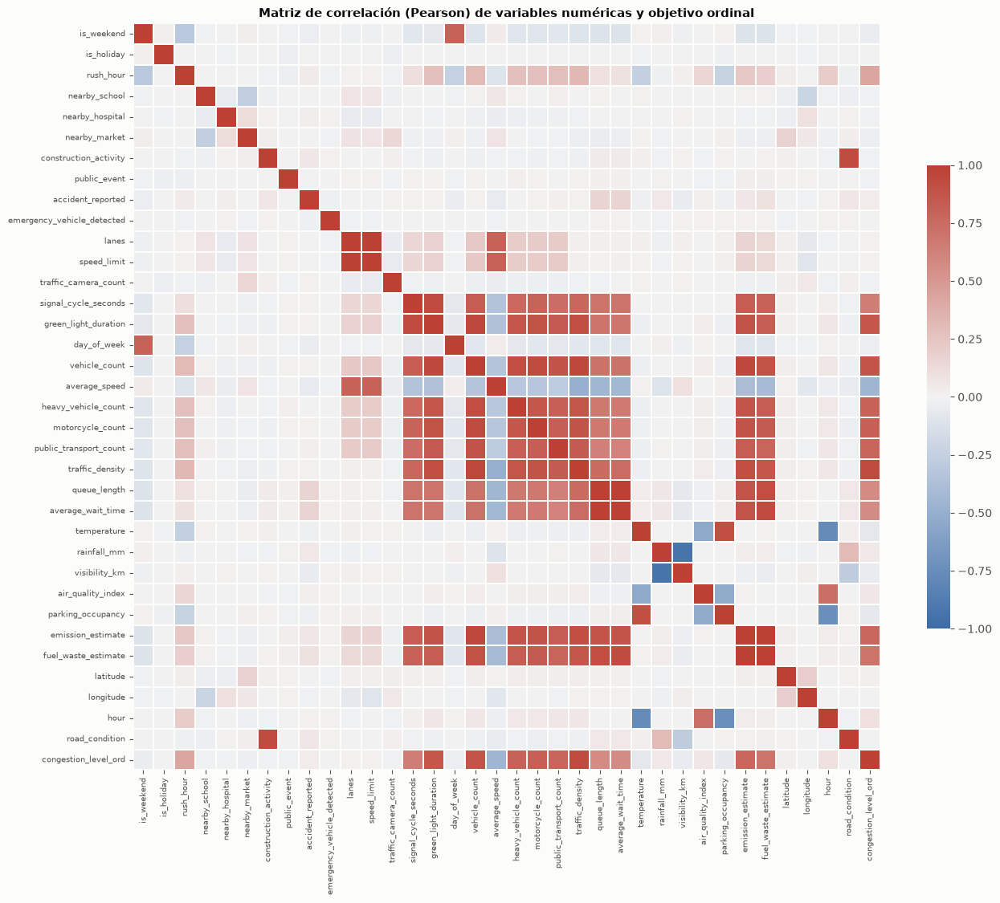

Correlación con el nivel de congestión (top 12):


,r
traffic_density,0.930
vehicle_count,0.879
green_light_duration,0.860
motorcycle_count,0.820
heavy_vehicle_count,0.805
public_transport_count,0.788
emission_estimate,0.774
fuel_waste_estimate,0.707
signal_cycle_seconds,0.652
queue_length,0.575


In [13]:
df_corr = df[NUMERICAS].copy()
df_corr["road_condition"] = df["road_condition"].map({v: i for i, v in enumerate(ORDINALES["road_condition"])})
df_corr[OBJETIVO + "_ord"] = df[OBJETIVO].map({c: i for i, c in enumerate(CLASES)})
corr = df_corr.corr()
fig, ax = plt.subplots(figsize=(15, 12.5))
sns.heatmap(corr, cmap=sns.diverging_palette(250, 15, s=75, l=45, as_cmap=True), center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, linecolor="#fcfcfb", cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Matriz de correlación (Pearson) de variables numéricas y objetivo ordinal")
ax.tick_params(labelsize=7)
guardar_figura(fig, "eda_correlacion")

top_corr = corr[OBJETIVO + "_ord"].drop(OBJETIVO + "_ord").sort_values(key=abs, ascending=False)
print("Correlación con el nivel de congestión (top 12):")
display(top_corr.head(12).round(3).to_frame("r"))
guardar_tabla(corr.round(4), "eda_correlacion")

## 5. Partición estratificada 70 / 15 / 15
Se divide una sola vez. El conjunto de **prueba es idéntico en los 8 casos**. El conjunto de validación
se usa para elegir hiperparámetros y para el *early stopping* de la red neuronal.

In [14]:
def particionar(df, semilla=SEMILLA):
    """Divide de forma estratificada en entrenamiento (70 %), validación (15 %) y prueba (15 %)."""
    X, y = df.drop(columns=OBJETIVO), df[OBJETIVO]
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=semilla)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=semilla)
    return [d.reset_index(drop=True) for d in (X_tr, X_va, X_te, y_tr, y_va, y_te)]


X_train_raw, X_val_raw, X_test_raw, y_train_raw, y_val, y_test = particionar(df)
tabla_particion = pd.DataFrame({n: s.value_counts().reindex(CLASES) for n, s in
                                [("entrenamiento", y_train_raw), ("validación", y_val), ("prueba", y_test)]})
tabla_particion.loc["Total"] = tabla_particion.sum()
display(tabla_particion)
guardar_tabla(tabla_particion, "particion")

,entrenamiento,validación,prueba
congestion_level,,,
Low,3111,667,667
Moderate,444,95,96
High,445,95,95
Severe,445,95,95
Total,4445,952,953


## 6. Funciones de preprocesamiento
### 6.1 Manejo de valores atípicos — Z-score (|z| > 3)
* **Método:** Z-score con umbral 3 sobre las 15 variables continuas (`CONTINUAS`). Media y desviación se
  ajustan **solo con entrenamiento**. Se eligió Z-score y no IQR porque varias variables tienen colas
  largas y mezclan dos regímenes (tráfico fluido y congestionado). Con IQR × 1.5, el 23.5 % de las filas
  saldrían marcadas como atípicas, la mayoría registros reales de congestión severa.
* **Sin outliers:** los valores detectados se **tratan con recorte** (*winsorización*) a media ± 3σ. Se
  recorta en lugar de eliminar porque eliminar borraría sobre todo registros `Severe` y alteraría el
  balance de clases.
* **Con outliers:** sobre el entrenamiento ya tratado se **inyectan outliers sintéticos** en exactamente
  el 5 % de los registros. Para cada registro elegido se modifican 1 o 2 variables continuas al azar con
  el valor media ± U(3.5, 6)·σ. La dirección respeta el dominio: hacia arriba en conteos y tiempos, hacia
  abajo en visibilidad, en cualquier sentido para la temperatura. `parking_occupancy` se excluye porque
  es un porcentaje acotado.

In [15]:
class TratadorOutliersZ:
    """Detecta outliers por Z-score (|z| > umbral) y los recorta a media ± umbral·σ.

    Las medias y desviaciones se ajustan (fit) únicamente con el conjunto de entrenamiento.
    """

    def __init__(self, columnas=CONTINUAS, umbral=3.0):
        self.columnas, self.umbral = columnas, umbral

    def fit(self, X):
        self.media_ = X[self.columnas].mean()
        self.std_ = X[self.columnas].std()
        return self

    def mascara(self, X):
        """Matriz booleana (filas × columnas) con True donde |z| > umbral.

        Se usa una tolerancia de 1e-6 para que los valores recortados exactamente en media ± 3σ no se
        cuenten como atípicos por errores de redondeo de punto flotante.
        """
        z = (X[self.columnas] - self.media_) / self.std_
        return z.abs() > self.umbral + 1e-6

    def transform(self, X):
        X = X.copy()
        lim_inf = self.media_ - self.umbral * self.std_
        lim_sup = self.media_ + self.umbral * self.std_
        X[self.columnas] = X[self.columnas].clip(lower=lim_inf, upper=lim_sup, axis=1)
        return X


DIRECCION_INYECCION = {"visibility_km": -1, "temperature": 0}     # -1 abajo, 0 cualquiera, +1 (defecto) arriba
CANDIDATAS_INYECCION = [c for c in CONTINUAS if c != "parking_occupancy"]


def inyectar_outliers(X, tratador, fraccion=0.05, semilla=SEMILLA):
    """Inyecta outliers sintéticos en `fraccion` de las filas de X.

    Devuelve (X_modificado, registro) donde `registro` documenta fila, variable, valor original y nuevo.
    """
    rng = np.random.default_rng(semilla)
    X = X.copy()
    n_out = int(round(fraccion * len(X)))
    filas = rng.choice(len(X), size=n_out, replace=False)
    registro = []
    for fila in filas:
        variables = rng.choice(CANDIDATAS_INYECCION, size=rng.integers(1, 3), replace=False)
        for var in variables:
            direccion = DIRECCION_INYECCION.get(var, 1) or rng.choice([-1, 1])
            nuevo = tratador.media_[var] + direccion * rng.uniform(3.5, 6.0) * tratador.std_[var]
            registro.append({"fila": int(fila), "variable": var, "original": X.at[fila, var], "nuevo": nuevo})
            X.at[fila, var] = nuevo
    return X, pd.DataFrame(registro)

### 6.2 Balanceo de clases — SMOTENC
* **Desbalanceado (BALANCEO = NO):** el entrenamiento conserva la distribución 70/10/10/10 del subconjunto.
* **Balanceado (BALANCEO = SI):** **SMOTENC** sobremuestrea las clases minoritarias hasta igualar a la
  mayoritaria. Se eligió SMOTENC porque genera registros sintéticos interpolados entre vecinos de la
  misma clase en lugar de duplicar filas (el sobremuestreo aleatorio favorece el sobreajuste) y no
  descarta información (el submuestreo dejaría solo unas 1780 filas). La variante *NC* trata
  correctamente las variables categóricas: les asigna la moda de los vecinos en vez de interpolar.
  También se tratan así las binarias y las discretas de pocos valores.
* Para que la búsqueda de vecinos no esté dominada por las variables de mayor magnitud, las numéricas se
  estandarizan temporalmente dentro de la función y luego se devuelven a su escala original. Las enteras se
  redondean.
* `class_weight` no se usa: el balanceo se hace en los datos para que los cuatro algoritmos (y el
  agrupamiento) reciban exactamente los mismos registros.

In [16]:
CATEGORICAS_SMOTE = NOMINALES + list(ORDINALES) + BINARIAS + DISCRETAS_POCOS_VALORES


def balancear_smotenc(X, y, semilla=SEMILLA):
    """Balancea (X, y) con SMOTENC hasta igualar todas las clases con la mayoritaria."""
    columnas = list(X.columns)
    numericas = [c for c in columnas if c not in CATEGORICAS_SMOTE]
    escalador = StandardScaler().fit(X[numericas])
    X_tmp = X.copy()
    X_tmp[numericas] = escalador.transform(X[numericas])
    idx_cat = [columnas.index(c) for c in CATEGORICAS_SMOTE]
    smote = SMOTENC(categorical_features=idx_cat, random_state=semilla, k_neighbors=5)
    X_bal, y_bal = smote.fit_resample(X_tmp, y)
    X_bal = pd.DataFrame(X_bal, columns=columnas)
    X_bal[numericas] = escalador.inverse_transform(X_bal[numericas].astype(float))
    for c in columnas:                                   # restaurar tipos originales
        if c in CATEGORICAS_SMOTE and X[c].dtype != object and not pd.api.types.is_string_dtype(X[c]):
            X_bal[c] = X_bal[c].astype(X[c].dtype)
        elif pd.api.types.is_integer_dtype(X[c]):
            X_bal[c] = np.round(X_bal[c].astype(float)).astype(X[c].dtype)
        elif pd.api.types.is_float_dtype(X[c]):
            X_bal[c] = X_bal[c].astype(float)
    return X_bal, pd.Series(y_bal, name=OBJETIVO).reset_index(drop=True)

### 6.3 Normalización: conversión de categóricas (CC) y escalado (ED)
* **CC (siempre):** *One-Hot Encoding* para las nominales (`city_zone`, `road_type`, `peak_period`,
  `weather_condition`, `iot_sensor_health`). No tienen orden, y un código entero les inventaría
  distancias falsas. *Codificación ordinal* para `road_condition` (Good < Wet < Poor), cuyo orden de
  severidad sí es real. Las binarias ya son 0/1.
* **ED (casos 5–8):** `StandardScaler` sobre todas las columnas no one-hot. Se prefirió frente a
  MinMaxScaler porque con outliers (inyectados en los casos 3, 4, 7 y 8) MinMax comprime casi todos los
  datos en un rango muy estrecho. La estandarización es menos sensible a eso y además es coherente con
  la detección por Z-score. Se ajusta (fit) solo con entrenamiento y se aplica (transform) a validación y
  prueba.

In [17]:
def construir_transformador(escalar):
    """ColumnTransformer con One-Hot (nominales), Ordinal (ordinales) y, si `escalar`, StandardScaler."""
    pasos = [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINALES)]
    ordinal = OrdinalEncoder(categories=[ORDINALES[c] for c in ORDINALES])
    if escalar:
        pasos.append(("ordinal", Pipeline([("cod", ordinal), ("esc", StandardScaler())]), list(ORDINALES)))
        pasos.append(("numericas", StandardScaler(), NUMERICAS))
    else:
        pasos.append(("ordinal", ordinal, list(ORDINALES)))
        pasos.append(("numericas", "passthrough", NUMERICAS))
    return ColumnTransformer(pasos, verbose_feature_names_out=False)

## 7. Construcción de los 8 casos (figura 1)
Orden de aplicación sobre el **entrenamiento**, siempre en este orden:
1. Tratamiento de outliers reales (recorte Z-score) → base limpia común.
2. Balanceo SMOTENC (si BALANCEO = SI).
3. Inyección del 5 % de outliers (si OUTLIERS = SI). Se hace después del balanceo para que los atípicos
   sean exactamente el 5 % del entrenamiento final y SMOTE no los propague por interpolación.
4. Ajuste del transformador CC (+ ED si aplica) con el entrenamiento y transformación de validación y prueba.

Validación y prueba no se modifican (son registros reales). Solo reciben la transformación CC/ED ajustada
con el entrenamiento. Por eso **la prueba es la misma en los 8 casos**. Los casos *i* e *i+4* comparten
exactamente los mismos registros de entrenamiento y solo se diferencian en el escalado.

In [18]:
CASOS = [
    {"caso": i + 1, "escalado": esc, "outliers": out, "balanceo": bal}
    for i, (esc, out, bal) in enumerate([(e, o, b) for e in (False, True) for o in (False, True) for b in (False, True)])
]


def etiqueta_caso(c):
    """Texto corto del caso, p. ej. 'C8 · ED(SI) · Out(SI) · Bal(SI)'."""
    s = lambda v: "SI" if v else "NO"
    return f"C{c['caso']} · ED({s(c['escalado'])}) · Out({s(c['outliers'])}) · Bal({s(c['balanceo'])})"


tratador_outliers = TratadorOutliersZ().fit(X_train_raw)
mascara_real = tratador_outliers.mascara(X_train_raw)
print(f"Outliers reales detectados en entrenamiento (|z|>3): {int(mascara_real.any(axis=1).sum())} filas "
      f"({100 * mascara_real.any(axis=1).mean():.2f} %), {int(mascara_real.values.sum())} valores")
display(mascara_real.sum().to_frame("valores_atipicos").T)
X_train_base = tratador_outliers.transform(X_train_raw)


def construir_registros_entrenamiento(outliers, balanceo):
    """Devuelve (X_train, y_train, registro_inyección) para la combinación outliers/balanceo dada."""
    X, y = X_train_base.copy(), y_train_raw.copy()
    if balanceo:
        X, y = balancear_smotenc(X, y)
    registro = pd.DataFrame()
    if outliers:
        X, registro = inyectar_outliers(X, tratador_outliers, fraccion=0.05)
    return X.reset_index(drop=True), y.reset_index(drop=True), registro


def preparar_caso(caso):
    """Construye todas las matrices de un caso: entrenamiento modificado y val/prueba transformados."""
    X_tr_df, y_tr, registro = construir_registros_entrenamiento(caso["outliers"], caso["balanceo"])
    transformador = construir_transformador(caso["escalado"]).fit(X_tr_df)
    return {
        **caso, "etiqueta": etiqueta_caso(caso), "transformador": transformador,
        "X_train_df": X_tr_df, "y_train": y_tr, "registro_outliers": registro,
        "X_train": transformador.transform(X_tr_df), "X_val": transformador.transform(X_val_raw),
        "X_test": transformador.transform(X_test_raw), "columnas": list(transformador.get_feature_names_out()),
    }


datos_casos = {c["caso"]: preparar_caso(c) for c in CASOS}

resumen_casos = []
for k, d in datos_casos.items():
    dist = d["y_train"].value_counts().reindex(CLASES)
    pct_out = 100 * tratador_outliers.mascara(d["X_train_df"]).any(axis=1).mean()
    resumen_casos.append({"caso": k, "ED": "SI" if d["escalado"] else "NO", "OUTLIERS": "SI" if d["outliers"] else "NO",
                          "BALANCEO": "SI" if d["balanceo"] else "NO", "n_train": len(d["y_train"]),
                          **{f"%{c}": round(100 * dist[c] / len(d["y_train"]), 1) for c in CLASES},
                          "%filas_outlier": round(pct_out, 2), "n_variables": d["X_train"].shape[1]})
resumen_casos = pd.DataFrame(resumen_casos).set_index("caso")
display(resumen_casos)
guardar_tabla(resumen_casos, "resumen_casos")

Outliers reales detectados en entrenamiento (|z|>3): 379 filas (8.53 %), 1368 valores


,vehicle_count,average_speed,heavy_vehicle_count,motorcycle_count,public_transport_count,traffic_density,queue_length,average_wait_time,temperature,rainfall_mm,visibility_km,air_quality_index,parking_occupancy,emission_estimate,fuel_waste_estimate
valores_atipicos,136,0,116,122,121,129,122,126,0,131,113,3,0,127,122


,ED,OUTLIERS,BALANCEO,n_train,%Low,%Moderate,%High,%Severe,%filas_outlier,n_variables
caso,,,,,,,,,,
1,NO,NO,NO,4445,70.0,10.0,10.0,10.0,0.00,56
2,NO,NO,SI,12444,25.0,25.0,25.0,25.0,0.00,56
3,NO,SI,NO,4445,70.0,10.0,10.0,10.0,4.99,56
4,NO,SI,SI,12444,25.0,25.0,25.0,25.0,5.00,56
5,SI,NO,NO,4445,70.0,10.0,10.0,10.0,0.00,56
6,SI,NO,SI,12444,25.0,25.0,25.0,25.0,0.00,56
7,SI,SI,NO,4445,70.0,10.0,10.0,10.0,4.99,56
8,SI,SI,SI,12444,25.0,25.0,25.0,25.0,5.00,56


In [19]:
reg = datos_casos[8]["registro_outliers"]
print(f"Caso 8: {reg.fila.nunique()} registros con outliers inyectados "
      f"({100 * reg.fila.nunique() / len(datos_casos[8]['y_train']):.2f} % del entrenamiento), {len(reg)} valores modificados.")
display(reg.groupby("variable").size().sort_values(ascending=False).to_frame("valores_inyectados").T)
display(reg.head(8).round(2))
guardar_tabla(reg.round(3), "outliers_inyectados_caso8")

Caso 8: 622 registros con outliers inyectados (5.00 % del entrenamiento), 947 valores modificados.


variable,rainfall_mm,fuel_waste_estimate,visibility_km,vehicle_count,heavy_vehicle_count,air_quality_index,average_speed,traffic_density,average_wait_time,temperature,emission_estimate,public_transport_count,motorcycle_count,queue_length
valores_inyectados,76,72,72,71,70,70,69,69,68,66,65,65,61,53


,fila,variable,original,nuevo
0,4309,heavy_vehicle_count,13.00,125.95
1,4309,air_quality_index,93.00,159.73
2,7411,average_speed,80.84,160.19
3,7411,heavy_vehicle_count,66.45,131.44
4,6778,traffic_density,109.31,349.92
5,6778,vehicle_count,983.56,3227.80
6,12078,air_quality_index,75.74,197.14
7,259,public_transport_count,9.00,103.95


### Tres registros de prueba fijos
Para cada caso y cada técnica se muestra la predicción sobre los **mismos tres registros del conjunto de
prueba** (uno de cada una de tres clases distintas), elegidos con la semilla del equipo.

In [20]:
rng_muestras = np.random.default_rng(SEMILLA)
IDX_PRUEBA_3 = [int(rng_muestras.choice(np.where(y_test.values == c)[0])) for c in ["Low", "High", "Severe"]]
display(X_test_raw.loc[IDX_PRUEBA_3, ["city_zone", "road_type", "hour", "vehicle_count", "average_speed",
                                     "traffic_density", "queue_length"]].assign(real=y_test[IDX_PRUEBA_3].values))

,city_zone,road_type,hour,vehicle_count,average_speed,traffic_density,queue_length,real
556,Suburban North,Highway,5,241,88.1,20.1,17.3,Low
427,Downtown Core,Arterial,17,1036,52.1,115.1,38.4,High
385,Suburban North,Arterial,13,1716,6.9,190.7,1726.8,Severe


---
# MÓDULO DE APRENDIZAJE SUPERVISADO
## 8. Funciones de entrenamiento y evaluación
* **Métricas:** accuracy, y precisión, recall y F1 con promedio **macro** (cada clase pesa igual). Con un
  test 70/10/10/10, el promedio ponderado o el accuracy premiarían a un modelo que solo acierta `Low`.
* **Selección de hiperparámetros:** con el conjunto de validación (F1-macro), salvo KNN, donde el
  enunciado pide validación cruzada de 5 folds.

In [21]:
NOMBRES_ALG = list(COLOR_ALG)


def metricas(y_true, y_pred):
    """Accuracy y precisión/recall/F1 macro."""
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, y_pred, average="macro", zero_division=0)}


def entrenar_arbol(d, profundidades=range(1, 21)):
    """Árbol de decisión: curvas de max_depth (Gini y Entropía) en train/val y modelo final Gini.

    Devuelve (modelo_final, curvas DataFrame, profundidad_elegida).
    """
    filas = []
    for criterio in ("gini", "entropy"):
        for p in profundidades:
            m = DecisionTreeClassifier(criterion=criterio, max_depth=p, random_state=SEMILLA).fit(d["X_train"], d["y_train"])
            filas.append({"criterio": criterio, "max_depth": p,
                          "acc_train": accuracy_score(d["y_train"], m.predict(d["X_train"])),
                          "acc_val": accuracy_score(y_val, m.predict(d["X_val"])),
                          "f1_val": f1_score(y_val, m.predict(d["X_val"]), average="macro")})
    curvas = pd.DataFrame(filas)
    gini = curvas[curvas.criterio == "gini"]
    mejor = int(gini.loc[gini.f1_val.idxmax(), "max_depth"])
    modelo = DecisionTreeClassifier(criterion="gini", max_depth=mejor, random_state=SEMILLA).fit(d["X_train"], d["y_train"])
    return modelo, curvas, mejor


def entrenar_knn(d, ks=range(1, 32, 2)):
    """KNN: elige k por accuracy promedio de validación cruzada estratificada de 5 folds.

    La CV se hace sobre los registros reales del entrenamiento (base tratada) y el balanceo SMOTENC, la
    inyección de outliers y el ajuste de CC/ED se repiten DENTRO de cada fold, solo con la parte de
    entrenamiento del fold. Hacer la CV directamente sobre el conjunto ya balanceado filtraría información:
    un registro sintético de validación tendría a sus 'padres' en el entrenamiento y la CV favorecería k=1.
    """
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    aciertos = {k: [] for k in ks}
    for i, (idx_tr, idx_va) in enumerate(cv.split(X_train_base, y_train_raw)):
        X_f, y_f = X_train_base.iloc[idx_tr].reset_index(drop=True), y_train_raw.iloc[idx_tr].reset_index(drop=True)
        if d["balanceo"]:
            X_f, y_f = balancear_smotenc(X_f, y_f, semilla=SEMILLA + i)
        if d["outliers"]:
            X_f, _ = inyectar_outliers(X_f, tratador_outliers, fraccion=0.05, semilla=SEMILLA + i)
        transf = construir_transformador(d["escalado"]).fit(X_f)
        Xtr_f, Xva_f = transf.transform(X_f), transf.transform(X_train_base.iloc[idx_va])
        for k in ks:
            pred = KNeighborsClassifier(n_neighbors=k).fit(Xtr_f, y_f).predict(Xva_f)
            aciertos[k].append(accuracy_score(y_train_raw.iloc[idx_va], pred))
    curva = pd.DataFrame([{"k": k, "acc_cv": np.mean(v), "std_cv": np.std(v)} for k, v in aciertos.items()])
    mejor = int(curva.loc[curva.acc_cv.idxmax(), "k"])
    return KNeighborsClassifier(n_neighbors=mejor).fit(d["X_train"], d["y_train"]), curva, mejor


def entrenar_svm(d, valores_C=(1, 10, 100)):
    """SVM con kernel RBF (gamma='scale'): elige C por F1-macro en validación."""
    res = []
    for C in valores_C:
        m = SVC(kernel="rbf", C=C, gamma="scale", cache_size=1000, random_state=SEMILLA).fit(d["X_train"], d["y_train"])
        res.append((f1_score(y_val, m.predict(d["X_val"]), average="macro"), C, m))
    f1v, C, modelo = max(res, key=lambda t: t[0])
    return modelo, pd.DataFrame([(c, f) for f, c, _ in res], columns=["C", "f1_val"]), C

### Red neuronal (Keras)
**Arquitectura y proceso de configuración.** Es un perceptrón multicapa totalmente conectado con salida
*softmax* de 4 neuronas y pérdida *sparse categorical cross-entropy*, optimizado con Adam
(lr = 1e-3, lotes de 64).

**Regularización vista en clase:**
* penalización **L2** en las capas densas (en todas las arquitecturas)
* **Dropout** (en todas las arquitecturas)
* **Batch Normalization** (en las arquitecturas B y C)

**Callbacks:**
* **EarlyStopping**: vigila `val_loss` con paciencia 15 y restaura los mejores pesos.
* **ReduceLROnPlateau**: multiplica el lr por 0.5 tras 5 épocas sin mejora.

Antes de entrenar los 8 casos se comparan 3 arquitecturas en el caso 8 con el conjunto de validación
(sección 9). La ganadora se usa en todos los casos para que la comparación entre preprocesamientos sea
justa.

In [22]:
ARQUITECTURAS = {
    "A: 64 · L2 · Dropout 0.2": {"capas": [64], "dropout": 0.2, "l2": 1e-4, "bn": False},
    "B: 128-64 · L2 · BN · Dropout 0.3": {"capas": [128, 64], "dropout": 0.3, "l2": 1e-4, "bn": True},
    "C: 256-128-64 · L2 · BN · Dropout 0.4": {"capas": [256, 128, 64], "dropout": 0.4, "l2": 1e-4, "bn": True},
}
ID_CLASE = {c: i for i, c in enumerate(CLASES)}


def construir_red(n_entradas, capas, dropout, l2, bn):
    """Crea y compila un MLP Keras con regularización L2, BatchNormalization y Dropout."""
    modelo = keras.Sequential([layers.Input(shape=(n_entradas,))])
    for unidades in capas:
        modelo.add(layers.Dense(unidades, activation="relu",
                                kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if bn:
            modelo.add(layers.BatchNormalization())
        modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(len(CLASES), activation="softmax"))
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


class RedNeuronal:
    """Envoltorio con interfaz tipo scikit-learn (fit / predict / predict_proba) para el MLP de Keras."""

    def __init__(self, config, epocas=200, lote=64):
        self.config, self.epocas, self.lote = config, epocas, lote

    def fit(self, X, y, X_val, y_val):
        fijar_semillas()
        self.modelo = construir_red(X.shape[1], **self.config)
        cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
        self.historia = self.modelo.fit(X.astype("float32"), y.map(ID_CLASE).values,
                                        validation_data=(X_val.astype("float32"), y_val.map(ID_CLASE).values),
                                        epochs=self.epocas, batch_size=self.lote, callbacks=cbs, verbose=0).history
        return self

    def predict_proba(self, X):
        return self.modelo.predict(X.astype("float32"), verbose=0)

    def predict(self, X):
        return np.array(CLASES)[self.predict_proba(X).argmax(axis=1)]

## 9. Configuración de la red neuronal (comparación de arquitecturas en el caso 8)

In [23]:
comparacion_redes = []
for nombre, cfg in ARQUITECTURAS.items():
    red = RedNeuronal(cfg).fit(datos_casos[8]["X_train"], datos_casos[8]["y_train"], datos_casos[8]["X_val"], y_val)
    comparacion_redes.append({"arquitectura": nombre, "parámetros": red.modelo.count_params(),
                              "épocas": len(red.historia["loss"]),
                              "f1_val": f1_score(y_val, red.predict(datos_casos[8]["X_val"]), average="macro"),
                              "acc_val": accuracy_score(y_val, red.predict(datos_casos[8]["X_val"]))})
comparacion_redes = pd.DataFrame(comparacion_redes).set_index("arquitectura")
display(comparacion_redes.round(4))
guardar_tabla(comparacion_redes.round(4), "configuracion_red")
ARQ_ELEGIDA = comparacion_redes.f1_val.idxmax()
print("Arquitectura elegida:", ARQ_ELEGIDA)
construir_red(datos_casos[8]["X_train"].shape[1], **ARQUITECTURAS[ARQ_ELEGIDA]).summary()

,parámetros,épocas,f1_val,acc_val
arquitectura,,,,
A: 64 · L2 · Dropout 0.2,3908,55,0.9337,0.9569
B: 128-64 · L2 · BN · Dropout 0.3,16580,25,0.9280,0.9538
C: 256-128-64 · L2 · BN · Dropout 0.4,57796,27,0.9277,0.9527


Arquitectura elegida: A: 64 · L2 · Dropout 0.2


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,908 (15.27 KB)

 Trainable params: 3,908 (15.27 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Funciones de visualización supervisada (sección 2.4)
PCA se usa **solo para visualizar**. Los modelos se entrenan siempre con todas las variables.
* **KNN:** se proyecta el entrenamiento a 2D. Se marca un registro de prueba y sus *k* vecinos,
  calculados por el modelo en el espacio completo.
* **SVM:** se crea una malla en el plano PCA y se lleva al espacio original con `inverse_transform`. El
  SVM entrenado (en todas las variables) predice cada punto. El color de la malla es la región de
  decisión del modelo real sobre el plano principal de los datos.

In [24]:
def dispersion_clases(ax, Z, y, alpha=0.35, s=10):
    """Dibuja puntos 2D coloreados (rampa ordinal) y con marcador distinto por clase."""
    for c in CLASES:
        m = np.asarray(y) == c
        ax.scatter(Z[m, 0], Z[m, 1], s=s, alpha=alpha, color=COLOR_CLASE[c], marker=MARCA_CLASE[c],
                   label=c, edgecolors="none")


def leyenda(ax, **kwargs):
    """Leyenda con marcadores opacos y de tamaño uniforme (los puntos del gráfico pueden ser transparentes)."""
    ley = ax.legend(**kwargs)
    for h in ley.legend_handles:
        if hasattr(h, "set_alpha"):
            h.set_alpha(1)
        if hasattr(h, "set_sizes"):
            h.set_sizes([30])
    return ley


def limites_robustos(Z, margen=0.05):
    """Límites del gráfico entre los percentiles 1 y 99 (evita que los outliers aplasten la vista)."""
    lo, hi = np.percentile(Z, 1, axis=0), np.percentile(Z, 99, axis=0)
    r = hi - lo
    return lo - margen * r, hi + margen * r


def graficar_visualizaciones_caso(d, modelos, curvas, num):
    """Figura compuesta del caso: importancia (árbol), max_depth vs accuracy, k vs accuracy,
    vecinos KNN (PCA) y regiones de decisión SVM (PCA)."""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    arbol, knn, svm = modelos["Árbol de decisión"], modelos["KNN"], modelos["SVM"]

    # (a) Importancia de características
    imp = pd.Series(arbol.feature_importances_, index=d["columnas"]).sort_values().tail(12)
    axes[0, 0].barh(imp.index, imp.values, color=COLOR_ALG["Árbol de decisión"], height=0.6)
    axes[0, 0].set_title("Árbol: importancia de características (top 12)")
    axes[0, 0].tick_params(axis="y", labelsize=8)
    axes[0, 0].grid(axis="y", visible=False)

    # (b) max_depth vs accuracy (Gini vs Entropía, train vs validación)
    ax = axes[0, 1]
    cv = curvas["arbol"]
    for criterio, color in (("gini", COLOR_PAR[0]), ("entropy", COLOR_PAR[1])):
        t = cv[cv.criterio == criterio]
        ax.plot(t.max_depth, t.acc_train, color=color, linestyle="--", linewidth=1.5, label=f"{criterio} · train")
        ax.plot(t.max_depth, t.acc_val, color=color, label=f"{criterio} · validación")
    ax.axvline(curvas["prof"], color=TINTA2, linewidth=1, linestyle=":")
    ax.annotate(f"elegido: {curvas['prof']}", (curvas["prof"], ax.get_ylim()[0]), xytext=(4, 6),
                textcoords="offset points", color=TINTA2, fontsize=8)
    ax.set_title("Árbol: max_depth vs accuracy")
    ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)

    # (c) k vs accuracy CV
    ax = axes[0, 2]
    ax.plot(curvas["knn"].k, curvas["knn"].acc_cv, color=COLOR_ALG["KNN"], marker="o", markersize=5)
    ax.axvline(curvas["k"], color=TINTA2, linewidth=1, linestyle=":")
    ax.set_title(f"KNN: k vs accuracy (CV 5 folds) — k elegido = {curvas['k']}")
    ax.set_xlabel("k"); ax.set_ylabel("accuracy promedio CV")

    # PCA (solo visualización)
    pca = PCA(n_components=2, random_state=SEMILLA).fit(d["X_train"])
    Z_tr = pca.transform(d["X_train"])
    lo, hi = limites_robustos(Z_tr)

    # (d) Vecinos KNN de un registro de prueba
    ax = axes[1, 0]
    dispersion_clases(ax, Z_tr, d["y_train"], alpha=0.18, s=8)
    consulta = d["X_test"][IDX_PRUEBA_3[1]:IDX_PRUEBA_3[1] + 1]
    _, vecinos = knn.kneighbors(consulta)
    Zq, Zv = pca.transform(consulta), Z_tr[vecinos[0]]
    for p in Zv:
        ax.plot([Zq[0, 0], p[0]], [Zq[0, 1], p[1]], color=TINTA2, linewidth=0.6, alpha=0.6)
    ax.scatter(Zv[:, 0], Zv[:, 1], s=60, facecolors="none", edgecolors=COLOR_ALG["KNN"], linewidths=1.6,
               label=f"{knn.n_neighbors} vecinos")
    ax.scatter(Zq[:, 0], Zq[:, 1], s=220, marker="*", color=COLOR_ALG["KNN"], edgecolors=TINTA, linewidths=0.8,
               label=f"consulta (real: {y_test[IDX_PRUEBA_3[1]]}, pred: {knn.predict(consulta)[0]})")
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_title("KNN: vecinos de un registro de prueba (PCA 2D)")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); leyenda(ax, fontsize=7, loc="best")

    # (e) Regiones de decisión SVM
    ax = axes[1, 1]
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 220), np.linspace(lo[1], hi[1], 220))
    malla = pca.inverse_transform(np.c_[xx.ravel(), yy.ravel()])
    pred = pd.Series(svm.predict(malla)).map(ID_CLASE).values.reshape(xx.shape)
    cmap = matplotlib.colors.ListedColormap([COLOR_CLASE[c] for c in CLASES])
    ax.contourf(xx, yy, pred, levels=np.arange(-0.5, 4), cmap=cmap, alpha=0.35)
    dispersion_clases(ax, pca.transform(d["X_test"]), y_test, alpha=0.8, s=12)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_title(f"SVM (RBF, C={curvas['C']}): regiones de decisión + prueba (PCA 2D)")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); leyenda(ax, fontsize=7)

    # (f) Curva de aprendizaje de la red
    ax = axes[1, 2]
    h = modelos["Red neuronal"].historia
    ax.plot(h["loss"], color=COLOR_ALG["Red neuronal"], linestyle="--", linewidth=1.5, label="pérdida train")
    ax.plot(h["val_loss"], color=COLOR_ALG["Red neuronal"], label="pérdida validación")
    ax.set_title(f"Red neuronal: pérdida por época ({len(h['loss'])} épocas, early stopping)")
    ax.set_xlabel("época"); ax.set_ylabel("cross-entropy"); ax.legend(fontsize=8)
    ax.set_yscale("log")

    fig.suptitle(f"Visualización de resultados — {d['etiqueta']}", fontsize=14, fontweight="bold")
    fig.tight_layout()
    guardar_figura(fig, f"sup_caso{num}_visualizaciones")


def graficar_arbol(modelo, d, num, profundidad_visible=3):
    """Dibuja el árbol solución (Gini) mostrando los primeros niveles e imprime sus reglas."""
    fig, ax = plt.subplots(figsize=(22, 8))
    plot_tree(modelo, max_depth=profundidad_visible, feature_names=d["columnas"], class_names=list(modelo.classes_),
              filled=False, impurity=True, proportion=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f"Árbol de decisión solución (Gini, max_depth={modelo.get_depth()}) — primeros "
                 f"{profundidad_visible} niveles — {d['etiqueta']}")
    guardar_figura(fig, f"sup_caso{num}_arbol")
    reglas = export_text(modelo, feature_names=d["columnas"], max_depth=profundidad_visible, decimals=2)
    print(reglas)
    return reglas

## 11. Entrenamiento y evaluación de los 8 casos

C1 · ED(NO) · Out(NO) · Bal(NO)  —  entrenamiento: (4445, 56)


Hiperparámetros → árbol max_depth=4 | KNN k=9 | SVM C=100 | red épocas=101


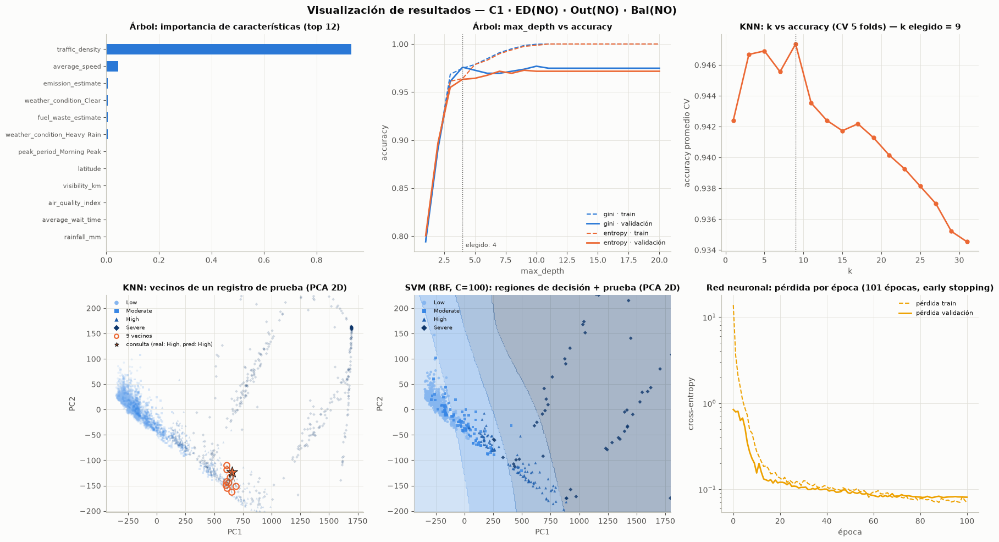

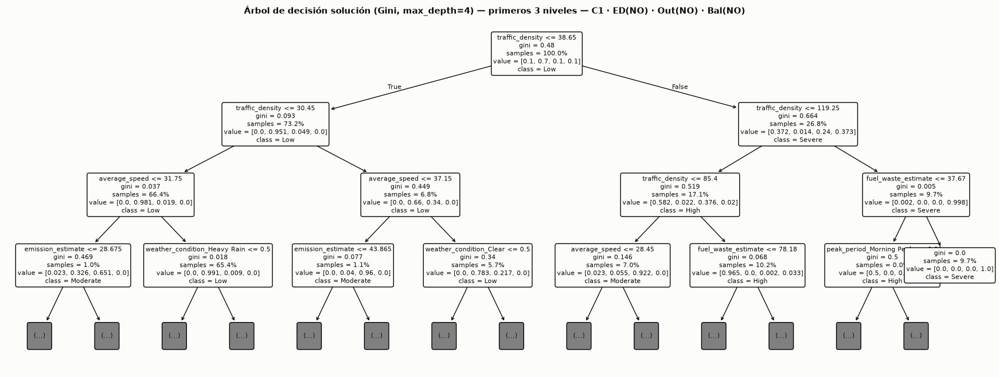

|--- traffic_density <= 38.65
|   |--- traffic_density <= 30.45
|   |   |--- average_speed <= 31.75
|   |   |   |--- emission_estimate <= 28.67
|   |   |   |   |--- class: Low
|   |   |   |--- emission_estimate >  28.67
|   |   |   |   |--- class: Moderate
|   |   |--- average_speed >  31.75
|   |   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |   |--- class: Low
|   |   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |   |--- class: Low
|   |--- traffic_density >  30.45
|   |   |--- average_speed <= 37.15
|   |   |   |--- emission_estimate <= 43.86
|   |   |   |   |--- class: Low
|   |   |   |--- emission_estimate >  43.86
|   |   |   |   |--- class: Moderate
|   |   |--- average_speed >  37.15
|   |   |   |--- weather_condition_Clear <= 0.50
|   |   |   |   |--- class: Moderate
|   |   |   |--- weather_condition_Clear >  0.50
|   |   |   |   |--- class: Low
|--- traffic_density >  38.65
|   |--- traffic_density <= 119.25
|   |   |--- traffic_density <= 85.40
| 

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9780,0.9674,0.9541,0.9602
KNN,0.9591,0.9434,0.9116,0.9242
SVM,0.9801,0.9661,0.9593,0.9624
Red neuronal,0.9748,0.9537,0.9574,0.9555


Tiempo del caso: 20.9 s
C2 · ED(NO) · Out(NO) · Bal(SI)  —  entrenamiento: (12444, 56)


Hiperparámetros → árbol max_depth=11 | KNN k=1 | SVM C=100 | red épocas=84


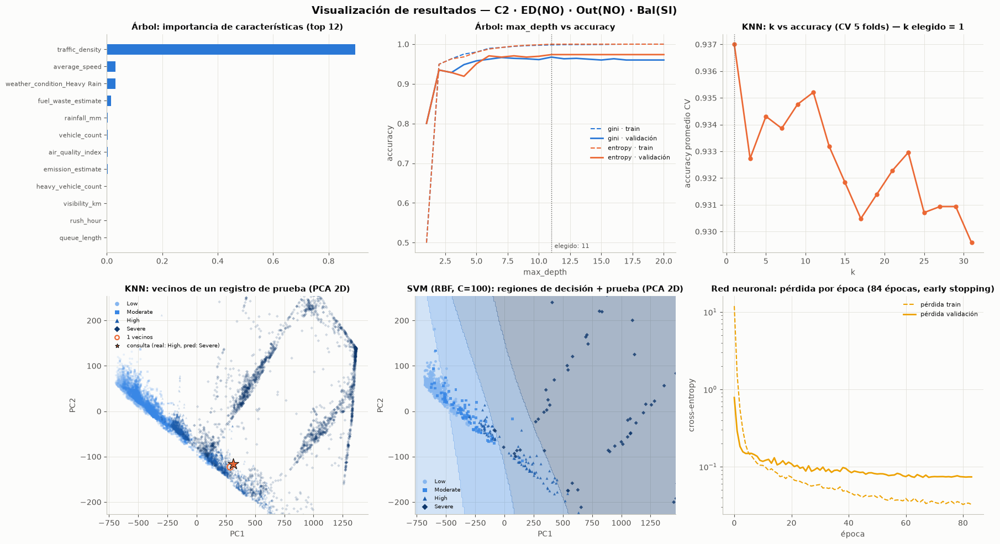

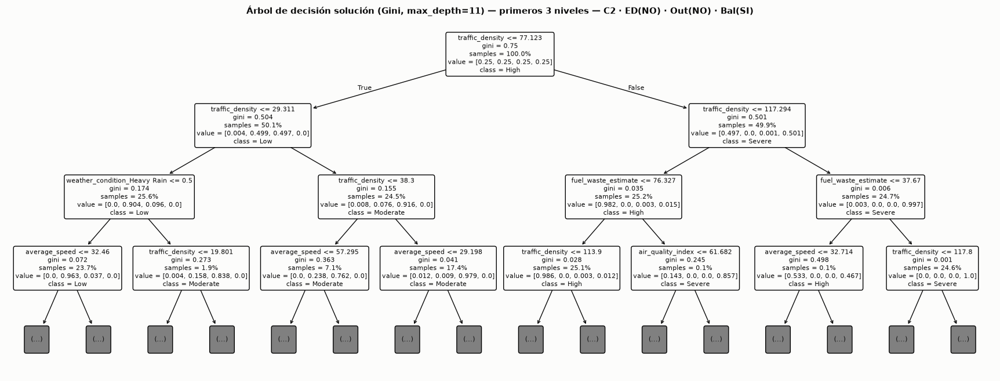

|--- traffic_density <= 77.12
|   |--- traffic_density <= 29.31
|   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |--- average_speed <= 32.46
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- average_speed >  32.46
|   |   |   |   |--- truncated branch of depth 8
|   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |--- traffic_density <= 19.80
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- traffic_density >  19.80
|   |   |   |   |--- truncated branch of depth 8
|   |--- traffic_density >  29.31
|   |   |--- traffic_density <= 38.30
|   |   |   |--- average_speed <= 57.29
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- average_speed >  57.29
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- traffic_density >  38.30
|   |   |   |--- average_speed <= 29.20
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- average_speed >  29.20
|   |   |   |   |--- truncated branch of depth 8
|--- traff

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9601,0.9255,0.9454,0.9350
KNN,0.9412,0.8979,0.9253,0.9103
SVM,0.9538,0.9090,0.9497,0.9241
Red neuronal,0.9717,0.9432,0.9630,0.9523


Tiempo del caso: 41.3 s
C3 · ED(NO) · Out(SI) · Bal(NO)  —  entrenamiento: (4445, 56)


Hiperparámetros → árbol max_depth=10 | KNN k=3 | SVM C=10 | red épocas=75


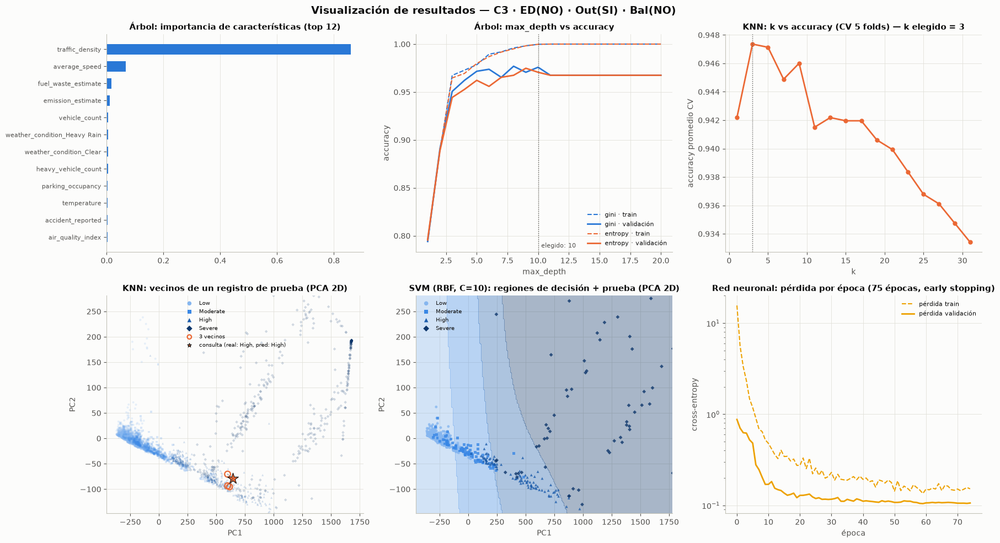

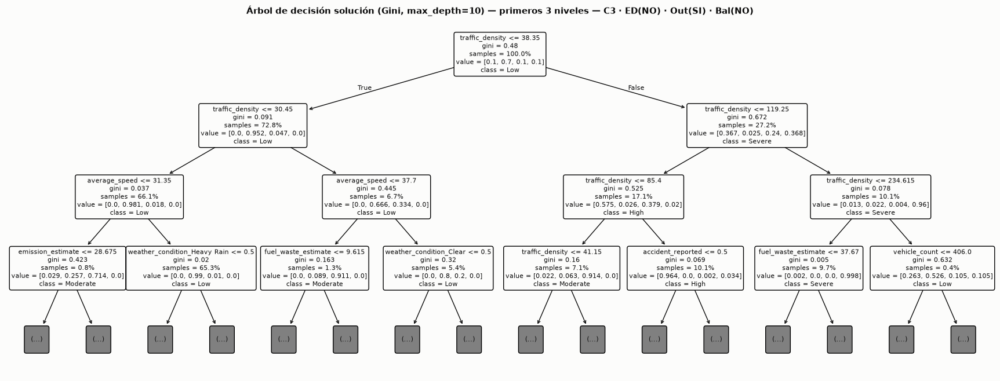

|--- traffic_density <= 38.35
|   |--- traffic_density <= 30.45
|   |   |--- average_speed <= 31.35
|   |   |   |--- emission_estimate <= 28.67
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- emission_estimate >  28.67
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- average_speed >  31.35
|   |   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- traffic_density >  30.45
|   |   |--- average_speed <= 37.70
|   |   |   |--- fuel_waste_estimate <= 9.62
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- fuel_waste_estimate >  9.62
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- average_speed >  37.70
|   |   |   |--- weather_condition_Clear <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- weather_condition_Clear >  0.50
|   |   |   |   |--- truncated 

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9748,0.9541,0.9529,0.9528
KNN,0.9622,0.9483,0.9217,0.9330
SVM,0.9549,0.9392,0.9009,0.9168
Red neuronal,0.9675,0.9428,0.9458,0.9441


Tiempo del caso: 18.8 s
C4 · ED(NO) · Out(SI) · Bal(SI)  —  entrenamiento: (12444, 56)


Hiperparámetros → árbol max_depth=7 | KNN k=1 | SVM C=10 | red épocas=27


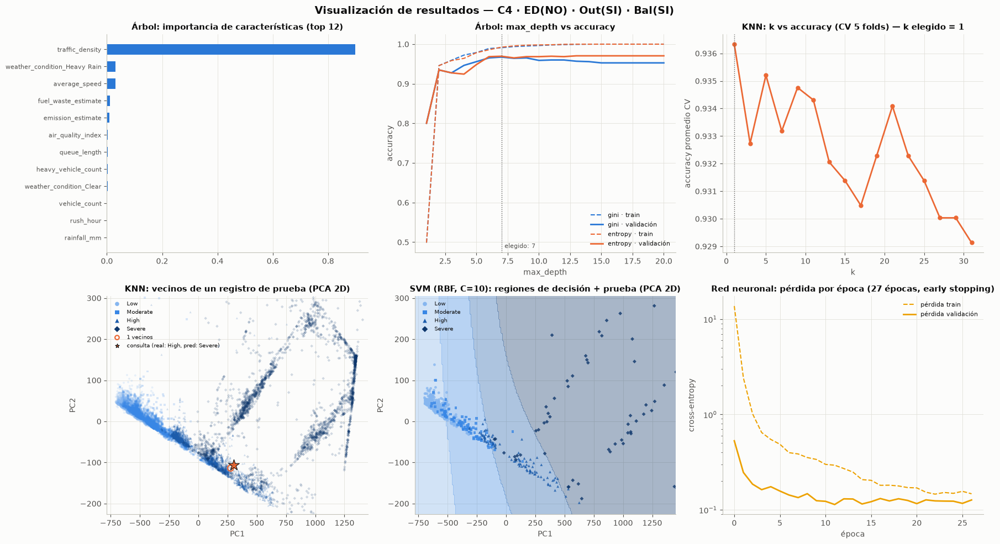

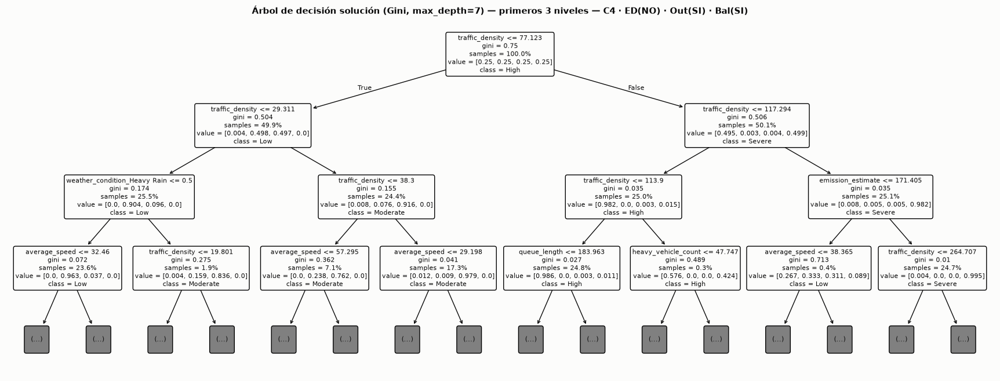

|--- traffic_density <= 77.12
|   |--- traffic_density <= 29.31
|   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |--- average_speed <= 32.46
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- average_speed >  32.46
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |--- traffic_density <= 19.80
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- traffic_density >  19.80
|   |   |   |   |--- truncated branch of depth 4
|   |--- traffic_density >  29.31
|   |   |--- traffic_density <= 38.30
|   |   |   |--- average_speed <= 57.29
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- average_speed >  57.29
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- traffic_density >  38.30
|   |   |   |--- average_speed <= 29.20
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- average_speed >  29.20
|   |   |   |   |--- truncated branch of depth 4
|--- traff

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9643,0.9307,0.9491,0.9394
KNN,0.9412,0.8971,0.9231,0.9088
SVM,0.9307,0.8870,0.9213,0.8978
Red neuronal,0.9612,0.9252,0.9525,0.9369


Tiempo del caso: 42.2 s
C5 · ED(SI) · Out(NO) · Bal(NO)  —  entrenamiento: (4445, 56)


Hiperparámetros → árbol max_depth=4 | KNN k=5 | SVM C=100 | red épocas=68


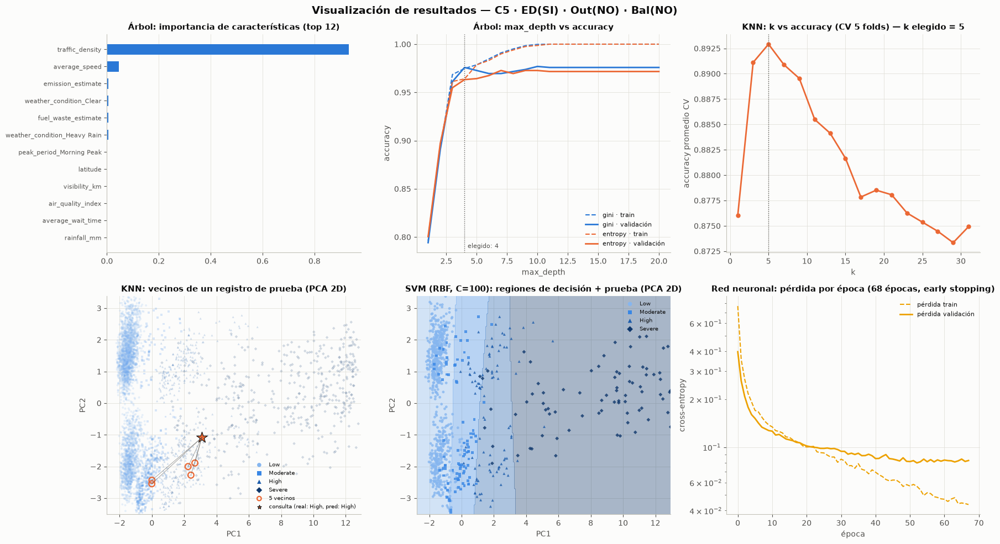

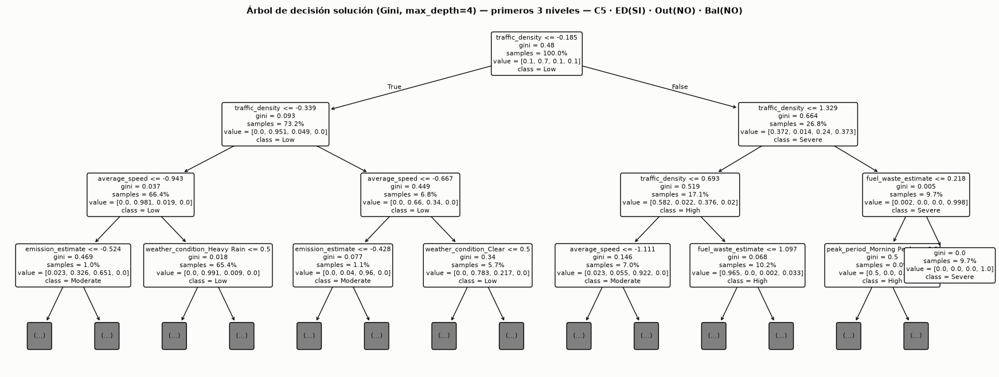

|--- traffic_density <= -0.18
|   |--- traffic_density <= -0.34
|   |   |--- average_speed <= -0.94
|   |   |   |--- emission_estimate <= -0.52
|   |   |   |   |--- class: Low
|   |   |   |--- emission_estimate >  -0.52
|   |   |   |   |--- class: Moderate
|   |   |--- average_speed >  -0.94
|   |   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |   |--- class: Low
|   |   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |   |--- class: Low
|   |--- traffic_density >  -0.34
|   |   |--- average_speed <= -0.67
|   |   |   |--- emission_estimate <= -0.43
|   |   |   |   |--- class: Low
|   |   |   |--- emission_estimate >  -0.43
|   |   |   |   |--- class: Moderate
|   |   |--- average_speed >  -0.67
|   |   |   |--- weather_condition_Clear <= 0.50
|   |   |   |   |--- class: Moderate
|   |   |   |--- weather_condition_Clear >  0.50
|   |   |   |   |--- class: Low
|--- traffic_density >  -0.18
|   |--- traffic_density <= 1.33
|   |   |--- traffic_density <= 0.69
|   |

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9780,0.9674,0.9541,0.9602
KNN,0.8898,0.8144,0.7814,0.7969
SVM,0.9549,0.9179,0.9324,0.9250
Red neuronal,0.9706,0.9476,0.9425,0.9443


Tiempo del caso: 21.1 s
C6 · ED(SI) · Out(NO) · Bal(SI)  —  entrenamiento: (12444, 56)


Hiperparámetros → árbol max_depth=11 | KNN k=3 | SVM C=100 | red épocas=44


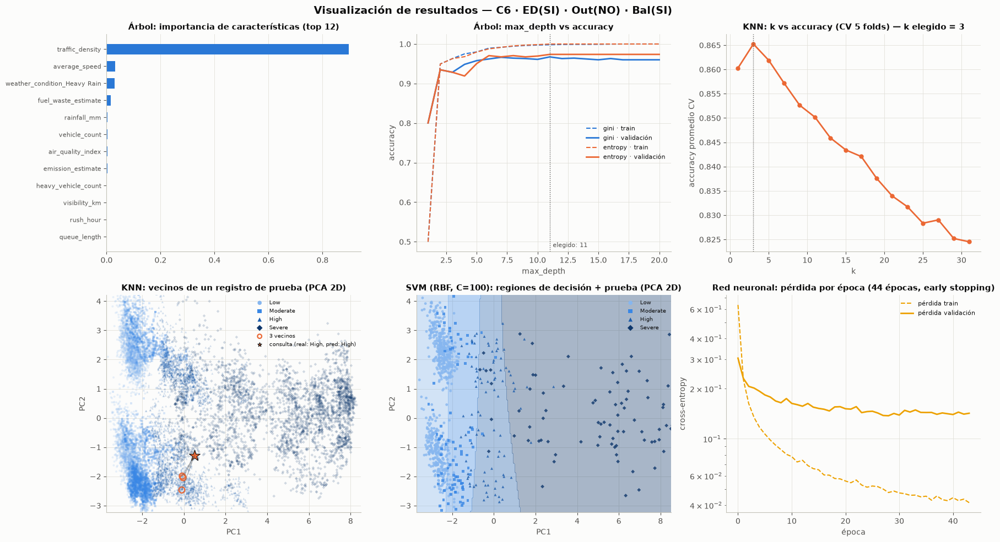

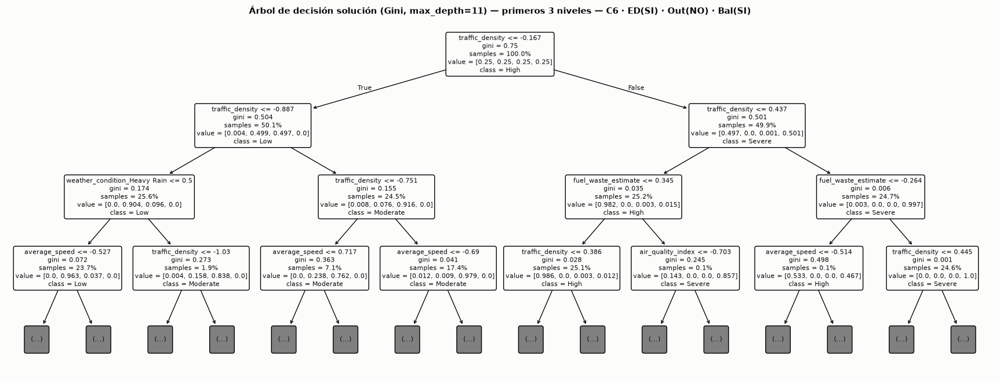

|--- traffic_density <= -0.17
|   |--- traffic_density <= -0.89
|   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |--- average_speed <= -0.53
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- average_speed >  -0.53
|   |   |   |   |--- truncated branch of depth 8
|   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |--- traffic_density <= -1.03
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- traffic_density >  -1.03
|   |   |   |   |--- truncated branch of depth 8
|   |--- traffic_density >  -0.89
|   |   |--- traffic_density <= -0.75
|   |   |   |--- average_speed <= 0.72
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- average_speed >  0.72
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- traffic_density >  -0.75
|   |   |   |--- average_speed <= -0.69
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- average_speed >  -0.69
|   |   |   |   |--- truncated branch of depth 8
|--- traffic

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9601,0.9255,0.9454,0.9350
KNN,0.8730,0.7936,0.7930,0.7891
SVM,0.9454,0.9079,0.9177,0.9120
Red neuronal,0.9496,0.9077,0.9350,0.9200


Tiempo del caso: 33.2 s
C7 · ED(SI) · Out(SI) · Bal(NO)  —  entrenamiento: (4445, 56)


Hiperparámetros → árbol max_depth=10 | KNN k=3 | SVM C=1 | red épocas=126


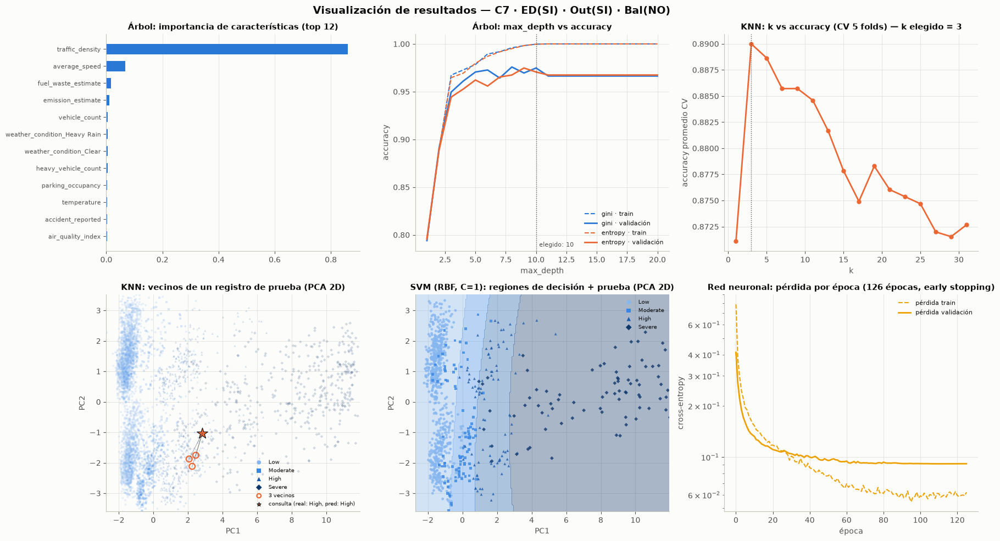

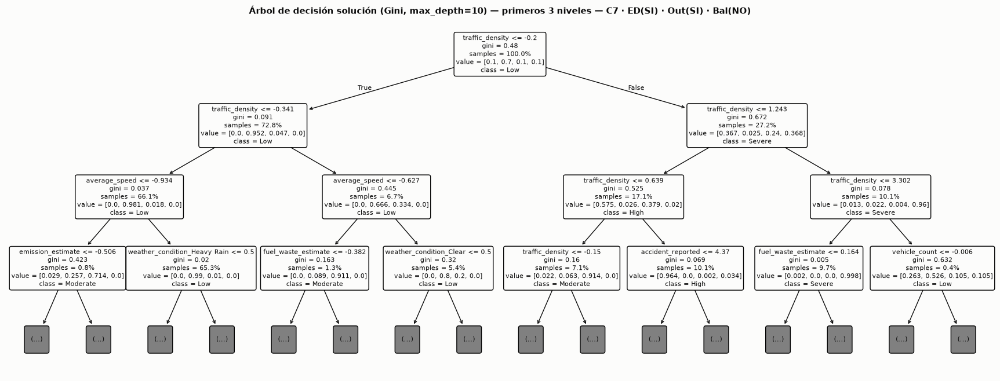

|--- traffic_density <= -0.20
|   |--- traffic_density <= -0.34
|   |   |--- average_speed <= -0.93
|   |   |   |--- emission_estimate <= -0.51
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- emission_estimate >  -0.51
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- average_speed >  -0.93
|   |   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- traffic_density >  -0.34
|   |   |--- average_speed <= -0.63
|   |   |   |--- fuel_waste_estimate <= -0.38
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- fuel_waste_estimate >  -0.38
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- average_speed >  -0.63
|   |   |   |--- weather_condition_Clear <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- weather_condition_Clear >  0.50
|   |   |   |   |--- truncate

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9748,0.9541,0.9529,0.9528
KNN,0.8877,0.8086,0.7738,0.7903
SVM,0.9360,0.9075,0.8807,0.8918
Red neuronal,0.9664,0.9385,0.9432,0.9404


Tiempo del caso: 27.4 s
C8 · ED(SI) · Out(SI) · Bal(SI)  —  entrenamiento: (12444, 56)


Hiperparámetros → árbol max_depth=7 | KNN k=3 | SVM C=100 | red épocas=55


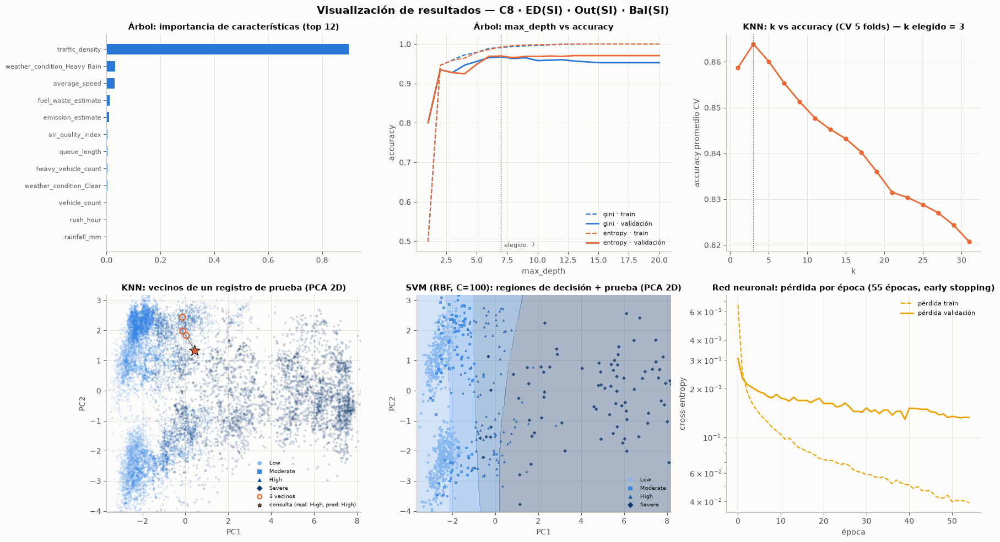

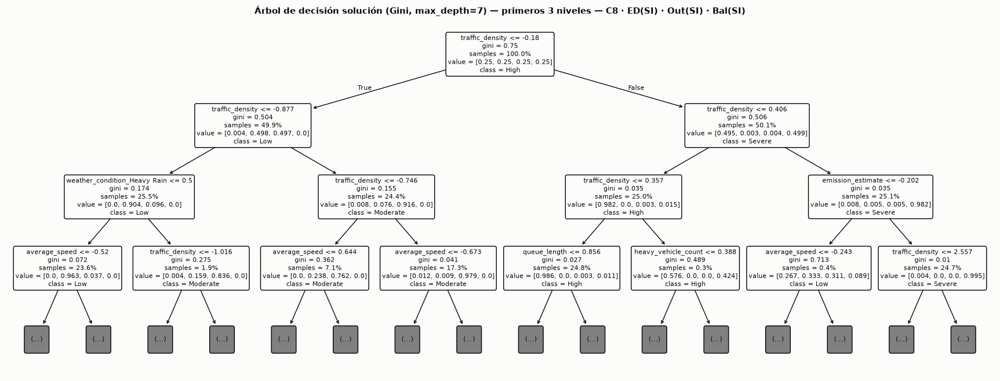

|--- traffic_density <= -0.18
|   |--- traffic_density <= -0.88
|   |   |--- weather_condition_Heavy Rain <= 0.50
|   |   |   |--- average_speed <= -0.52
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- average_speed >  -0.52
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- weather_condition_Heavy Rain >  0.50
|   |   |   |--- traffic_density <= -1.02
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- traffic_density >  -1.02
|   |   |   |   |--- truncated branch of depth 4
|   |--- traffic_density >  -0.88
|   |   |--- traffic_density <= -0.75
|   |   |   |--- average_speed <= 0.64
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- average_speed >  0.64
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- traffic_density >  -0.75
|   |   |   |--- average_speed <= -0.67
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- average_speed >  -0.67
|   |   |   |   |--- truncated branch of depth 4
|--- traffic

,accuracy,precision,recall,f1
algoritmo,,,,
Árbol de decisión,0.9643,0.9307,0.9491,0.9394
KNN,0.8678,0.7826,0.7845,0.7798
SVM,0.9318,0.8908,0.8904,0.8895
Red neuronal,0.9433,0.8954,0.9327,0.9115


Tiempo del caso: 38.7 s


In [25]:
resultados_sup, predicciones_3, modelos_casos, reportes = [], [], {}, {}
for num, d in datos_casos.items():
    t0 = time.time()
    print("=" * 100, f"\n{d['etiqueta']}  —  entrenamiento: {d['X_train'].shape}")
    arbol, curva_arbol, prof = entrenar_arbol(d)
    knn, curva_knn, k = entrenar_knn(d)
    svm, curva_svm, C = entrenar_svm(d)
    red = RedNeuronal(ARQUITECTURAS[ARQ_ELEGIDA]).fit(d["X_train"], d["y_train"], d["X_val"], y_val)
    modelos = {"Árbol de decisión": arbol, "KNN": knn, "SVM": svm, "Red neuronal": red}
    modelos_casos[num] = modelos
    print(f"Hiperparámetros → árbol max_depth={prof} | KNN k={k} | SVM C={C} | red épocas={len(red.historia['loss'])}")

    for nombre, m in modelos.items():
        pred = m.predict(d["X_test"])
        resultados_sup.append({"caso": num, "ED": "SI" if d["escalado"] else "NO",
                               "OUTLIERS": "SI" if d["outliers"] else "NO",
                               "BALANCEO": "SI" if d["balanceo"] else "NO", "algoritmo": nombre, **metricas(y_test, pred)})
        reportes[(num, nombre)] = classification_report(y_test, pred, labels=CLASES, digits=3, output_dict=True)
        p3 = m.predict(d["X_test"][IDX_PRUEBA_3])
        for j, idx in enumerate(IDX_PRUEBA_3):
            predicciones_3.append({"caso": num, "algoritmo": nombre, "registro_prueba": idx,
                                   "real": y_test[idx], "predicho": p3[j]})

    graficar_visualizaciones_caso(d, modelos, {"arbol": curva_arbol, "prof": prof, "knn": curva_knn, "k": k, "C": C}, num)
    graficar_arbol(arbol, d, num)
    tabla_caso = pd.DataFrame([r for r in resultados_sup if r["caso"] == num]).set_index("algoritmo")
    display(tabla_caso[["accuracy", "precision", "recall", "f1"]].round(4))
    print(f"Tiempo del caso: {time.time() - t0:.1f} s")

resultados_sup = pd.DataFrame(resultados_sup)
predicciones_3 = pd.DataFrame(predicciones_3)

## 12. Tabla de la figura 1

In [26]:
figura1 = resultados_sup.pivot_table(index=["caso", "ED", "OUTLIERS", "BALANCEO"], columns="algoritmo",
                                     values=["accuracy", "precision", "recall", "f1"])
figura1 = figura1.swaplevel(0, 1, axis=1).reindex(columns=pd.MultiIndex.from_product(
    [NOMBRES_ALG, ["accuracy", "precision", "recall", "f1"]]))
figura1.columns.names = ["algoritmo", "métrica"]
display(figura1.round(4))
guardar_tabla(figura1.round(4), "figura1_supervisado")
guardar_tabla(resultados_sup.round(4), "resultados_supervisado_largo")

algoritmo                 Árbol de decisión                                KNN                                SVM                           Red neuronal                          
métrica                            accuracy precision  recall      f1 accuracy precision  recall      f1 accuracy precision  recall      f1     accuracy precision  recall      f1
caso ED OUTLIERS BALANCEO                                                                                                                                                         
1    NO NO       NO                  0.9780    0.9674  0.9541  0.9602   0.9591    0.9434  0.9116  0.9242   0.9801    0.9661  0.9593  0.9624       0.9748    0.9537  0.9574  0.9555
2    NO NO       SI                  0.9601    0.9255  0.9454  0.9350   0.9412    0.8979  0.9253  0.9103   0.9538    0.9090  0.9497  0.9241       0.9717    0.9432  0.9630  0.9523
3    NO SI       NO                  0.9748    0.9541  0.9529  0.9528   0.9622    0.9483  0.9217  0.9330   0.9549    0.9392  0.9009  0.9168       0.9675    0.9428  0.9458  0.9441
4    NO SI       SI                  0.9643    0.9307  0.9491  0.9394   0.9412    0.8971  0.9231  0.9088   0.9307    0.8870  0.9213  0.8978       0.9612    0.9252  0.9525  0.9369
5    SI NO       NO                  0.9780    0.9674  0.9541  0.9602   0.8898    0.8144  0.7814  0.7969   0.9549    0.9179  0.9324  0.9250       0.9706    0.9476  0.9425  0.9443
6    SI NO       SI                  0.9601    0.9255  0.9454  0.9350   0.8730    0.7936  0.7930  0.7891   0.9454    0.9079  0.9177  0.9120       0.9496    0.9077  0.9350  0.9200
7    SI SI       NO                  0.9748    0.9541  0.9529  0.9528   0.8877    0.8086  0.7738  0.7903   0.9360    0.9075  0.8807  0.8918       0.9664    0.9385  0.9432  0.9404
8    SI SI       SI                  0.9643    0.9307  0.9491  0.9394   0.8678    0.7826  0.7845  0.7798   0.9318    0.8908  0.8904  0.8895       0.9433    0.8954  0.9327  0.9115

### Predicción de los tres registros de prueba en cada caso y técnica

In [27]:
tabla_p3 = predicciones_3.assign(r=lambda t: "reg " + t.registro_prueba.astype(str) + " (real " + t.real + ")") \
    .pivot_table(index=["caso", "algoritmo"], columns="r", values="predicho", aggfunc="first")
display(tabla_p3)
guardar_tabla(tabla_p3, "predicciones_3_registros_supervisado")
print("Aciertos sobre los 3 registros:",
      f"{(predicciones_3.real == predicciones_3.predicho).sum()} de {len(predicciones_3)}")

r                      reg 385 (real Severe) reg 427 (real High) reg 556 (real Low)
caso algoritmo                                                                     
1    KNN                              Severe                High                Low
     Red neuronal                     Severe                High                Low
     SVM                              Severe                High                Low
     Árbol de decisión                Severe                High                Low
2    KNN                              Severe              Severe                Low
     Red neuronal                     Severe                High                Low
     SVM                                High                High                Low
     Árbol de decisión                Severe              Severe                Low
3    KNN                              Severe                High                Low
     Red neuronal                        Low              Severe                Low
     SVM                                 Low                High                Low
     Árbol de decisión                Severe              Severe                Low
4    KNN                              Severe              Severe                Low
     Red neuronal                     Severe                High                Low
     SVM                                 Low                High                Low
     Árbol de decisión                Severe              Severe                Low
5    KNN                              Severe                High                Low
     Red neuronal                     Severe                High                Low
     SVM                              Severe                High                Low
     Árbol de decisión                Severe                High                Low
6    KNN                              Severe                High                Low
     Red neuronal                     Severe                High                Low
     SVM                                 Low                High                Low
     Árbol de decisión                Severe              Severe                Low
7    KNN                              Severe                High                Low
     Red neuronal                     Severe                High                Low
     SVM                                 Low                High                Low
     Árbol de decisión                Severe              Severe                Low
8    KNN                              Severe                High                Low
     Red neuronal                     Severe                High                Low
     SVM                                 Low                High                Low
     Árbol de decisión                Severe              Severe                Low

Aciertos sobre los 3 registros: 80 de 96


## 13. Gráficas comparativas de F1-score

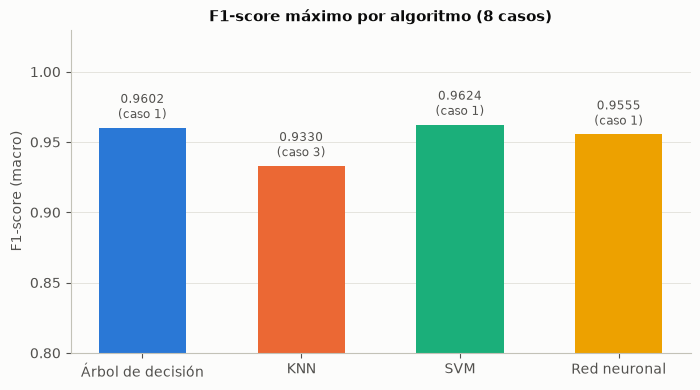

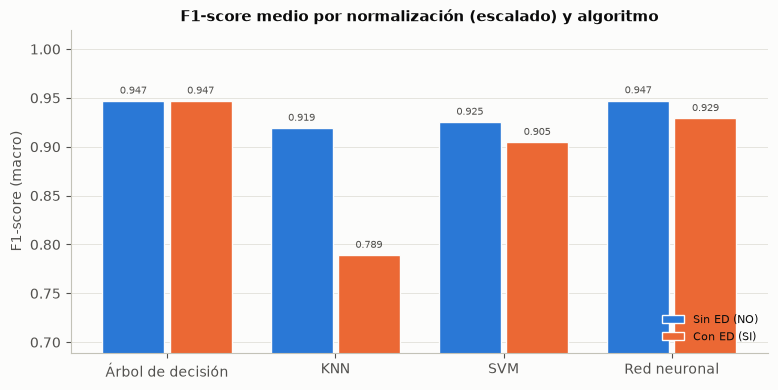

ED,Sin ED (NO),Con ED (SI)
algoritmo,,
Árbol de decisión,0.9469,0.9469
KNN,0.9191,0.7890
SVM,0.9253,0.9046
Red neuronal,0.9472,0.9290


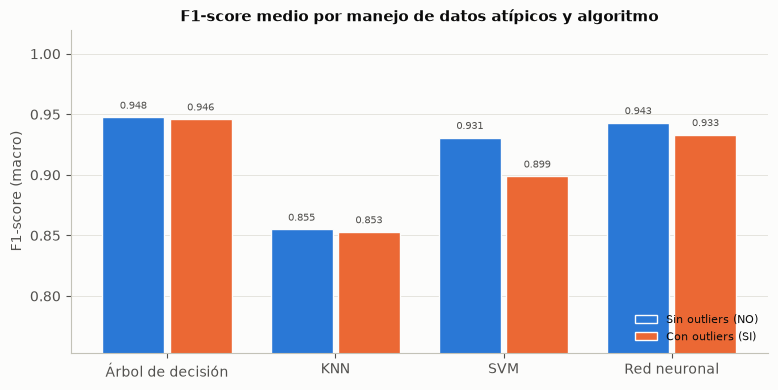

OUTLIERS,Sin outliers (NO),Con outliers (SI)
algoritmo,,
Árbol de decisión,0.9476,0.9461
KNN,0.8551,0.8530
SVM,0.9309,0.8990
Red neuronal,0.9430,0.9332


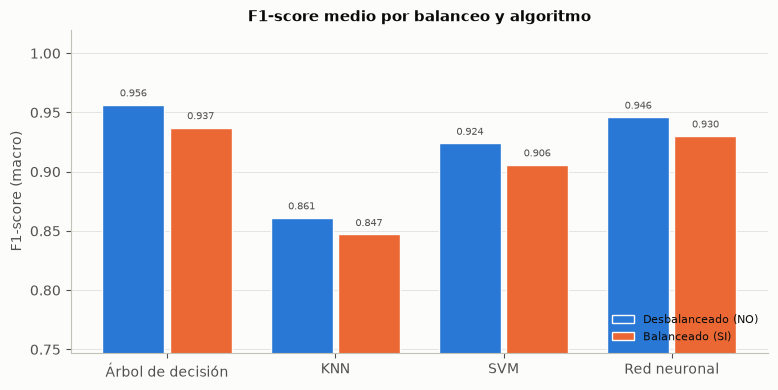

BALANCEO,Desbalanceado (NO),Balanceado (SI)
algoritmo,,
Árbol de decisión,0.9565,0.9372
KNN,0.8611,0.8470
SVM,0.9240,0.9058
Red neuronal,0.9461,0.9302


In [28]:
def barras_agrupadas(ax, tabla, colores, titulo, etiqueta_y="F1-score (macro)"):
    """Diagrama de barras agrupadas: filas de `tabla` = algoritmos, columnas = niveles comparados."""
    n = tabla.shape[1]
    ancho = 0.8 / n
    x = np.arange(len(tabla))
    for i, col in enumerate(tabla.columns):
        barras = ax.bar(x + (i - (n - 1) / 2) * ancho, tabla[col].values, width=ancho * 0.92,
                        color=colores[i], label=col, edgecolor="#fcfcfb", linewidth=1)
        for b in barras:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f"{b.get_height():.3f}",
                    ha="center", va="bottom", fontsize=7.5, color=TINTA2)
    ax.set_xticks(x, tabla.index)
    ax.set_title(titulo)
    ax.set_ylabel(etiqueta_y)
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8, loc="lower right")


fig, ax = plt.subplots(figsize=(8, 4.2))
f1_max = resultados_sup.groupby("algoritmo").f1.max().reindex(NOMBRES_ALG)
barras = ax.bar(NOMBRES_ALG, f1_max.values, color=[COLOR_ALG[a] for a in NOMBRES_ALG], width=0.55)
for b, a in zip(barras, NOMBRES_ALG):
    caso = int(resultados_sup.loc[resultados_sup[resultados_sup.algoritmo == a].f1.idxmax(), "caso"])
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.004, f"{b.get_height():.4f}\n(caso {caso})",
            ha="center", va="bottom", fontsize=8.5, color=TINTA2)
ax.set_ylim(min(0.8, f1_max.min() - 0.05), 1.03)
ax.set_title("F1-score máximo por algoritmo (8 casos)")
ax.set_ylabel("F1-score (macro)"); ax.grid(axis="x", visible=False)
guardar_figura(fig, "sup_f1_maximo")

agrupaciones = [("ED", "normalización (escalado)", {"NO": "Sin ED (NO)", "SI": "Con ED (SI)"}),
                ("OUTLIERS", "manejo de datos atípicos", {"NO": "Sin outliers (NO)", "SI": "Con outliers (SI)"}),
                ("BALANCEO", "balanceo", {"NO": "Desbalanceado (NO)", "SI": "Balanceado (SI)"})]
for col, nombre, renombre in agrupaciones:
    tabla = resultados_sup.pivot_table(index="algoritmo", columns=col, values="f1", aggfunc="mean") \
        .reindex(NOMBRES_ALG)[["NO", "SI"]].rename(columns=renombre)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    barras_agrupadas(ax, tabla, COLOR_PAR, f"F1-score medio por {nombre} y algoritmo")
    ax.set_ylim(max(0, tabla.values.min() - 0.1), 1.02)
    guardar_figura(fig, f"sup_f1_medio_{col.lower()}")
    display(tabla.round(4))
    guardar_tabla(tabla.round(4), f"f1_medio_{col.lower()}")

## 14. Matrices de confusión y reporte por clase (caso 8 y resumen de todos los casos)

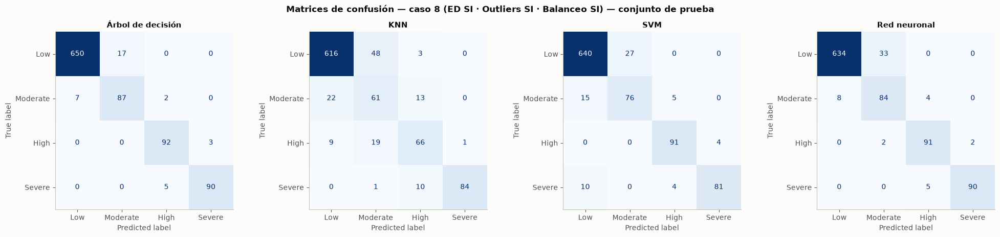

--- Árbol de decisión (caso 8) ---
              precision    recall  f1-score   support

         Low      0.989     0.975     0.982       667
    Moderate      0.837     0.906     0.870        96
        High      0.929     0.968     0.948        95
      Severe      0.968     0.947     0.957        95

    accuracy                          0.964       953
   macro avg      0.931     0.949     0.939       953
weighted avg      0.966     0.964     0.965       953

--- KNN (caso 8) ---
              precision    recall  f1-score   support

         Low      0.952     0.924     0.938       667
    Moderate      0.473     0.635     0.542        96
        High      0.717     0.695     0.706        95
      Severe      0.988     0.884     0.933        95

    accuracy                          0.868       953
   macro avg      0.783     0.784     0.780       953
weighted avg      0.884     0.868     0.874       953

--- SVM (caso 8) ---
              precision    recall  f1-score   support

              precision    recall  f1-score   support

         Low      0.988     0.951     0.969       667
    Moderate      0.706     0.875     0.781        96
        High      0.910     0.958     0.933        95
      Severe      0.978     0.947     0.963        95

    accuracy                          0.943       953
   macro avg      0.895     0.933     0.911       953
weighted avg      0.951     0.943     0.946       953



In [29]:
d8 = datos_casos[8]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (nombre, m) in zip(axes, modelos_casos[8].items()):
    cm = confusion_matrix(y_test, m.predict(d8["X_test"]), labels=CLASES)
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nombre); ax.grid(False)
fig.suptitle("Matrices de confusión — caso 8 (ED SI · Outliers SI · Balanceo SI) — conjunto de prueba",
             fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "sup_caso8_matrices_confusion")

for nombre, m in modelos_casos[8].items():
    print(f"--- {nombre} (caso 8) ---")
    print(classification_report(y_test, m.predict(d8["X_test"]), labels=CLASES, digits=3))

clase                     Low  Moderate   High  Severe
caso algoritmo                                        
1    KNN                0.991     0.729  0.989   0.937
     Red neuronal       0.987     0.906  0.968   0.968
     SVM                0.994     0.906  0.979   0.958
     Árbol de decisión  0.994     0.885  0.989   0.947
2    KNN                0.952     0.823  0.968   0.958
     Red neuronal       0.978     0.938  0.968   0.968
     SVM                0.957     0.979  0.979   0.884
     Árbol de decisión  0.970     0.885  0.958   0.968
3    KNN                0.990     0.760  0.989   0.947
     Red neuronal       0.982     0.885  0.968   0.947
     SVM                0.991     0.792  0.979   0.842
     Árbol de decisión  0.990     0.906  0.989   0.926
4    KNN                0.954     0.823  0.968   0.947
     Red neuronal       0.967     0.927  0.979   0.937
     SVM                0.937     0.906  0.979   0.863
     Árbol de decisión  0.975     0.906  0.968   0.947
5    KNN                0.963     0.500  0.768   0.895
     Red neuronal       0.990     0.865  0.979   0.937
     SVM                0.970     0.844  0.947   0.968
     Árbol de decisión  0.994     0.885  0.989   0.947
6    KNN                0.927     0.667  0.695   0.884
     Red neuronal       0.960     0.865  0.968   0.947
     SVM                0.964     0.854  0.958   0.895
     Árbol de decisión  0.970     0.885  0.958   0.968
7    KNN                0.964     0.542  0.705   0.884
     Red neuronal       0.982     0.865  0.979   0.947
     SVM                0.973     0.760  0.968   0.821
     Árbol de decisión  0.990     0.906  0.989   0.926
8    KNN                0.924     0.635  0.695   0.884
     Red neuronal       0.951     0.875  0.958   0.947
     SVM                0.960     0.792  0.958   0.853
     Árbol de decisión  0.975     0.906  0.968   0.947

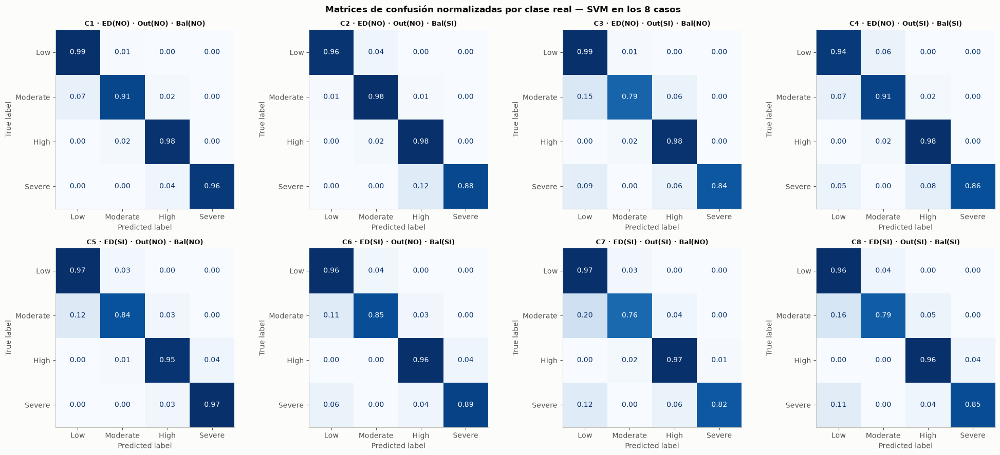

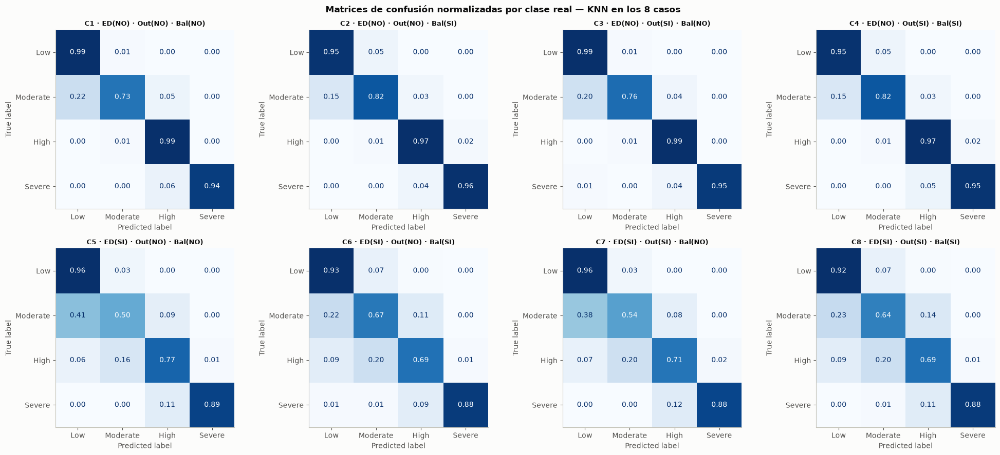

In [30]:
por_clase = pd.DataFrame([{"caso": num, "algoritmo": alg, "clase": c, "recall": rep[c]["recall"],
                           "precision": rep[c]["precision"], "f1": rep[c]["f1-score"]}
                          for (num, alg), rep in reportes.items() for c in CLASES])
recall_clase = por_clase.pivot_table(index=["caso", "algoritmo"], columns="clase", values="recall")[CLASES]
display(recall_clase.round(3))
guardar_tabla(por_clase.round(4), "metricas_por_clase")

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, num in zip(axes.ravel(), datos_casos):
    m = modelos_casos[num]["SVM"]
    cm = confusion_matrix(y_test, m.predict(datos_casos[num]["X_test"]), labels=CLASES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
    ax.set_title(datos_casos[num]["etiqueta"], fontsize=9); ax.grid(False)
fig.suptitle("Matrices de confusión normalizadas por clase real — SVM en los 8 casos", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "sup_matrices_svm_8casos")

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, num in zip(axes.ravel(), datos_casos):
    m = modelos_casos[num]["KNN"]
    cm = confusion_matrix(y_test, m.predict(datos_casos[num]["X_test"]), labels=CLASES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
    ax.set_title(datos_casos[num]["etiqueta"], fontsize=9); ax.grid(False)
fig.suptitle("Matrices de confusión normalizadas por clase real — KNN en los 8 casos", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "sup_matrices_knn_8casos")

## 15. Curvas ROC y Precision-Recall — caso 8
Problema multiclase → estrategia **uno-contra-resto**. Puntajes usados:
* `predict_proba` para el árbol, KNN y la red.
* `decision_function` para SVM (evita el costoso ajuste de Platt y el ranking es el mismo).

Se grafica el promedio **macro** (cada clase pesa igual) y además las curvas por clase.

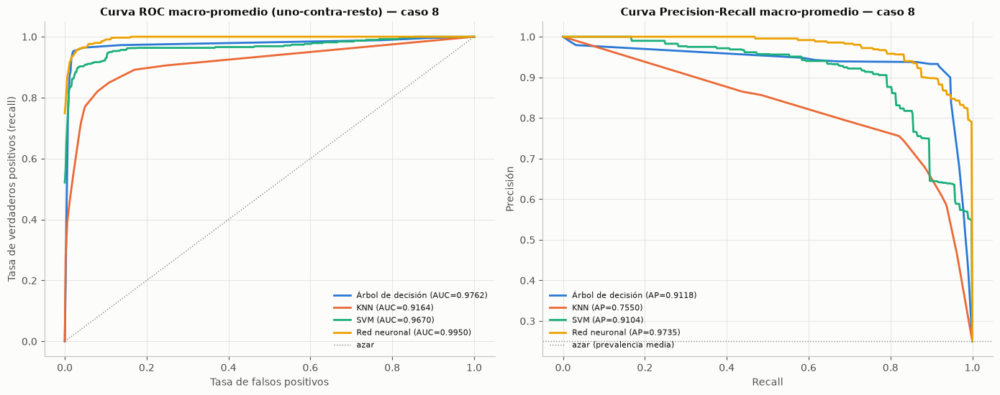

,AUC_ROC_macro,AP_macro,AUC_Low,AUC_Moderate,AUC_High,AUC_Severe,AP_Low,AP_Moderate,AP_High,AP_Severe
algoritmo,,,,,,,,,,
Árbol de decisión,0.9762,0.9118,0.9854,0.9555,0.9791,0.9849,0.9897,0.8302,0.8927,0.9346
KNN,0.9164,0.7550,0.9419,0.8580,0.8984,0.9672,0.9598,0.4287,0.7043,0.9271
SVM,0.9670,0.9104,0.9938,0.8909,0.9952,0.9883,0.9973,0.7499,0.9556,0.9388
Red neuronal,0.9950,0.9735,0.9959,0.9860,0.9985,0.9996,0.9982,0.9136,0.9860,0.9964


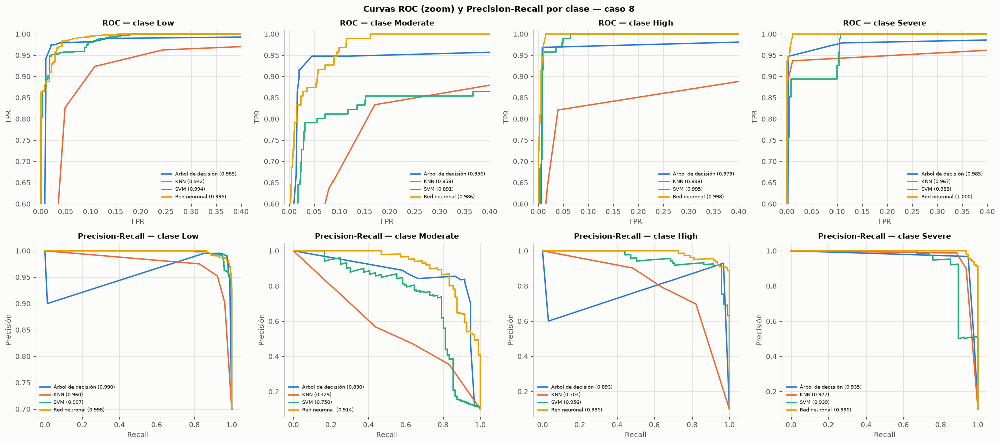

In [31]:
def puntajes(modelo, X):
    """Puntajes por clase (columnas en el orden de CLASES) para construir curvas ROC/PR."""
    if isinstance(modelo, SVC):
        s = modelo.decision_function(X)
    else:
        s = modelo.predict_proba(X)
    if isinstance(modelo, RedNeuronal):
        return s
    orden = [list(modelo.classes_).index(c) for c in CLASES]
    return s[:, orden]


Y_bin = label_binarize(y_test, classes=CLASES)
rejilla = np.linspace(0, 1, 501)
resumen_curvas, curvas_clase = [], {}
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5.6))
for nombre, m in modelos_casos[8].items():
    S = puntajes(m, d8["X_test"])
    tpr_m, prec_m = np.zeros_like(rejilla), np.zeros_like(rejilla)
    curvas_clase[nombre] = []
    for i, c in enumerate(CLASES):
        fpr, tpr, _ = roc_curve(Y_bin[:, i], S[:, i])
        prec, rec, _ = precision_recall_curve(Y_bin[:, i], S[:, i])
        tpr_m += np.interp(rejilla, fpr, tpr)
        # precisión interpolada: para cada recall r, la máxima precisión alcanzable con recall >= r
        # (precision_recall_curve entrega el recall en orden decreciente, por eso se acumula en ese orden)
        prec_interp = np.maximum.accumulate(prec)
        prec_m += np.interp(rejilla, rec[::-1], prec_interp[::-1])
        curvas_clase[nombre].append((fpr, tpr, auc(fpr, tpr), rec, prec, average_precision_score(Y_bin[:, i], S[:, i])))
    tpr_m /= len(CLASES); prec_m /= len(CLASES)
    auc_macro = np.mean([cc[2] for cc in curvas_clase[nombre]])
    ap_macro = average_precision_score(Y_bin, S, average="macro")
    resumen_curvas.append({"algoritmo": nombre, "AUC_ROC_macro": auc_macro, "AP_macro": ap_macro,
                           **{f"AUC_{c}": curvas_clase[nombre][i][2] for i, c in enumerate(CLASES)},
                           **{f"AP_{c}": curvas_clase[nombre][i][5] for i, c in enumerate(CLASES)}})
    ax_roc.plot(rejilla, tpr_m, color=COLOR_ALG[nombre], label=f"{nombre} (AUC={auc_macro:.4f})")
    ax_pr.plot(rejilla, prec_m, color=COLOR_ALG[nombre], label=f"{nombre} (AP={ap_macro:.4f})")
ax_roc.plot([0, 1], [0, 1], color=COLOR_RUIDO, linestyle=":", linewidth=1, label="azar")
ax_roc.set_title("Curva ROC macro-promedio (uno-contra-resto) — caso 8")
ax_roc.set_xlabel("Tasa de falsos positivos"); ax_roc.set_ylabel("Tasa de verdaderos positivos (recall)")
ax_roc.legend(fontsize=8, loc="lower right")
ax_pr.axhline(Y_bin.mean(), color=COLOR_RUIDO, linestyle=":", linewidth=1, label="azar (prevalencia media)")
ax_pr.set_title("Curva Precision-Recall macro-promedio — caso 8")
ax_pr.set_xlabel("Recall"); ax_pr.set_ylabel("Precisión"); ax_pr.legend(fontsize=8, loc="lower left")
fig.tight_layout()
guardar_figura(fig, "sup_caso8_roc_pr")

resumen_curvas = pd.DataFrame(resumen_curvas).set_index("algoritmo")
display(resumen_curvas.round(4))
guardar_tabla(resumen_curvas.round(4), "roc_pr_caso8")

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for i, c in enumerate(CLASES):
    for nombre in modelos_casos[8]:
        fpr, tpr, a, rec, prec, ap = curvas_clase[nombre][i]
        axes[0, i].plot(fpr, tpr, color=COLOR_ALG[nombre], label=f"{nombre} ({a:.3f})")
        axes[1, i].plot(rec, prec, color=COLOR_ALG[nombre], label=f"{nombre} ({ap:.3f})")
    axes[0, i].set_title(f"ROC — clase {c}"); axes[0, i].set_xlabel("FPR"); axes[0, i].set_ylabel("TPR")
    axes[1, i].set_title(f"Precision-Recall — clase {c}"); axes[1, i].set_xlabel("Recall"); axes[1, i].set_ylabel("Precisión")
    axes[0, i].legend(fontsize=7, loc="lower right"); axes[1, i].legend(fontsize=7, loc="lower left")
    axes[0, i].set_xlim(-0.01, 0.4); axes[0, i].set_ylim(0.6, 1.01)
fig.suptitle("Curvas ROC (zoom) y Precision-Recall por clase — caso 8", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "sup_caso8_roc_pr_por_clase")

### Resumen de las curvas de aprendizaje de la red neuronal en los 8 casos

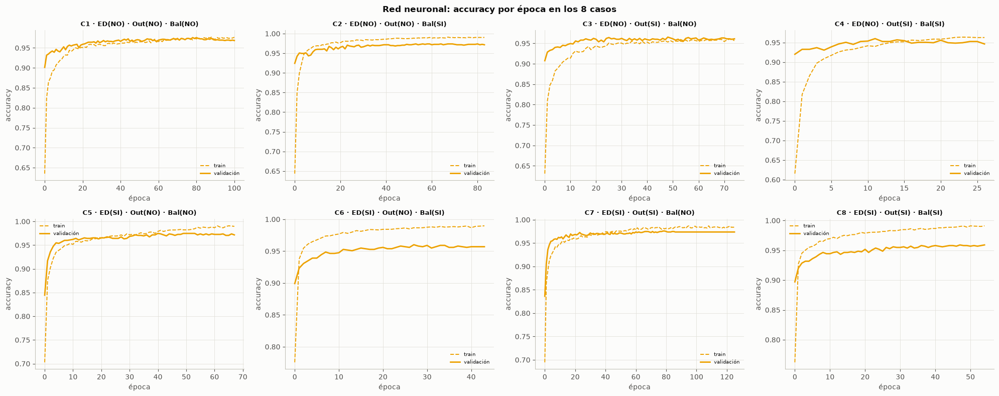

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey=False)
for ax, num in zip(axes.ravel(), datos_casos):
    h = modelos_casos[num]["Red neuronal"].historia
    ax.plot(h["accuracy"], color=COLOR_ALG["Red neuronal"], linestyle="--", linewidth=1.4, label="train")
    ax.plot(h["val_accuracy"], color=COLOR_ALG["Red neuronal"], label="validación")
    ax.set_title(datos_casos[num]["etiqueta"], fontsize=9)
    ax.set_xlabel("época"); ax.set_ylabel("accuracy"); ax.legend(fontsize=7)
fig.suptitle("Red neuronal: accuracy por época en los 8 casos", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "sup_red_curvas_8casos")

---
# MÓDULO DE APRENDIZAJE NO SUPERVISADO
## 16. Datasets de la figura 2
**Correspondencia con el módulo supervisado.** Cada caso *i* de la figura 2 usa exactamente los mismos
registros del entrenamiento del caso *i* de la figura 1, con el mismo tratamiento de outliers, el mismo
balanceo SMOTENC y el mismo transformador CC/ED. Después se descarta la variable objetivo:
* casos con BALANCEO = SI: 4 × 3111 registros
* casos con BALANCEO = NO: los 4445 de la distribución 70/10/10/10

La etiqueta original se guarda aparte y solo se usa para la **validación externa** (ARI, NMI y tabla de
contingencia), nunca para entrenar. Los tres registros de prueba se asignan a un cluster con el mismo
transformador.

In [33]:
resumen_ns = pd.DataFrame([{"caso": n, "registros": d["X_train"].shape[0], "variables": d["X_train"].shape[1],
                            "ED": "SI" if d["escalado"] else "NO", "OUTLIERS": "SI" if d["outliers"] else "NO",
                            "BALANCEO": "SI" if d["balanceo"] else "NO",
                            "origen": f"X_train del caso {n} supervisado (sin {OBJETIVO})"}
                           for n, d in datos_casos.items()]).set_index("caso")
display(resumen_ns)
guardar_tabla(resumen_ns, "figura2_datasets_no_supervisado")

,registros,variables,ED,OUTLIERS,BALANCEO,origen
caso,,,,,,
1,4445,56,NO,NO,NO,X_train del caso 1 supervisado (sin congestion...
2,12444,56,NO,NO,SI,X_train del caso 2 supervisado (sin congestion...
3,4445,56,NO,SI,NO,X_train del caso 3 supervisado (sin congestion...
4,12444,56,NO,SI,SI,X_train del caso 4 supervisado (sin congestion...
5,4445,56,SI,NO,NO,X_train del caso 5 supervisado (sin congestion...
6,12444,56,SI,NO,SI,X_train del caso 6 supervisado (sin congestion...
7,4445,56,SI,SI,NO,X_train del caso 7 supervisado (sin congestion...
8,12444,56,SI,SI,SI,X_train del caso 8 supervisado (sin congestion...


## 17. Funciones de agrupamiento
* **K-Means:** se recorre K = 2…10 con inicialización k-means++, `n_init=10` y la semilla del equipo. Se
  grafican la inercia (SSE, método del codo) y el silhouette.
  * El silhouette del barrido se estima con una muestra de 4000 puntos para reducir el costo, que es
    O(n²). El de la tabla final se calcula con todos los puntos.
  * El **K óptimo** es el de mayor silhouette, contrastado con el codo de la inercia.
* **DBSCAN:**
  * **MinPts = 2 × número de variables.**
  * **ε** se toma en el codo del gráfico de k-distancia (k = MinPts). El codo se detecta como el punto
    más alejado de la recta que une los extremos de la curva normalizada (método *Kneedle*).
  * El silhouette se calcula **excluyendo el ruido**.
  * Si con el ε del codo salen menos de 2 clusters (silhouette indefinido), se documenta y se reporta
    además el mejor ε de un análisis de sensibilidad (0.3×–1.5× ε del codo).

In [34]:
def barrido_kmeans(X, ks=range(2, 11)):
    """Inercia y silhouette (muestra de 4000) para cada K."""
    filas = []
    for k in ks:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEMILLA).fit(X)
        sil = silhouette_score(X, km.labels_, sample_size=min(4000, len(X)), random_state=SEMILLA)
        filas.append({"K": k, "inercia": km.inertia_, "silhouette": sil})
    return pd.DataFrame(filas)


def codo(y):
    """Índice del codo de una curva (punto más alejado de la recta entre sus extremos, curva normalizada)."""
    y = np.asarray(y, dtype=float)
    x = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    a, b = np.array([x[0], yn[0]]), np.array([x[-1], yn[-1]])
    dist = np.abs(np.cross(b - a, np.c_[x, yn] - a)) / np.linalg.norm(b - a)
    return int(dist.argmax())


def k_distancias(X, min_pts):
    """Distancia al MinPts-ésimo vecino más cercano de cada punto, ordenada ascendentemente."""
    nn = NearestNeighbors(n_neighbors=min_pts).fit(X)
    dist, _ = nn.kneighbors(X)
    return np.sort(dist[:, -1])


def evaluar_dbscan(X, eps, min_pts):
    """Ajusta DBSCAN y devuelve (modelo, n_clusters, %ruido, silhouette sin ruido o NaN)."""
    m = DBSCAN(eps=eps, min_samples=min_pts, n_jobs=-1).fit(X)
    etiquetas = m.labels_
    n_cl = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    no_ruido = etiquetas != -1
    sil = silhouette_score(X[no_ruido], etiquetas[no_ruido]) if n_cl >= 2 else np.nan
    return m, n_cl, 100 * (~no_ruido).mean(), sil


def asignar_dbscan(modelo, X_train, X_nuevo):
    """Asigna puntos nuevos al cluster del punto núcleo más cercano si está a distancia ≤ ε; si no, ruido (-1)."""
    nucleos = X_train[modelo.core_sample_indices_]
    if len(nucleos) == 0:
        return np.full(len(X_nuevo), -1)
    dist, idx = NearestNeighbors(n_neighbors=1).fit(nucleos).kneighbors(X_nuevo)
    etiquetas = modelo.labels_[modelo.core_sample_indices_][idx[:, 0]]
    return np.where(dist[:, 0] <= modelo.eps, etiquetas, -1)


def graficar_no_supervisado(d, barrido, k_opt, km, kdist, idx_codo, eps, min_pts, db, num):
    """Figura compuesta: codo, silhouette vs K, k-distancia, clusters K-Means y DBSCAN en PCA 2D."""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    ax = axes[0, 0]
    ax.plot(barrido.K, barrido.inercia, color=COLOR_PAR[0], marker="o", markersize=5)
    ax.axvline(k_opt, color=TINTA2, linestyle=":", linewidth=1)
    ax.set_title("K-Means: método del codo (inercia/SSE vs K)"); ax.set_xlabel("K"); ax.set_ylabel("inercia")
    ax = axes[0, 1]
    ax.plot(barrido.K, barrido.silhouette, color=COLOR_PAR[1], marker="o", markersize=5)
    ax.axvline(k_opt, color=TINTA2, linestyle=":", linewidth=1)
    ax.set_title(f"K-Means: silhouette vs K — K óptimo = {k_opt}"); ax.set_xlabel("K"); ax.set_ylabel("silhouette")
    ax = axes[0, 2]
    ax.plot(np.arange(len(kdist)), kdist, color=COLOR_PAR[0], linewidth=1.5)
    ax.scatter([idx_codo], [kdist[idx_codo]], color=COLOR_PAR[1], s=60, zorder=3, label=f"codo: ε={kdist[idx_codo]:.3g}")
    if not np.isclose(eps, kdist[idx_codo]):
        ax.axhline(eps, color=COLOR_PAR[1], linestyle=":", linewidth=1.2, label=f"ε usado = {eps:.3g}")
    ax.set_title(f"DBSCAN: gráfico de k-distancia (k = MinPts = {min_pts})")
    ax.set_xlabel("puntos ordenados"); ax.set_ylabel(f"distancia al {min_pts}-ésimo vecino"); ax.legend(fontsize=8)

    pca = PCA(n_components=2, random_state=SEMILLA).fit(d["X_train"])
    Z = pca.transform(d["X_train"])
    lo, hi = limites_robustos(Z)
    paleta = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
    ax = axes[1, 0]
    for c in range(km.n_clusters):
        m = km.labels_ == c
        ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.4, color=paleta[c % 8], label=f"cluster {c} (n={m.sum()})",
                   edgecolors="none")
    Zc = pca.transform(km.cluster_centers_)
    ax.scatter(Zc[:, 0], Zc[:, 1], marker="X", s=220, color=TINTA, edgecolors="#fcfcfb", linewidths=1.5,
               label="centroides")
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_title(f"K-Means (K={km.n_clusters}) en PCA 2D"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    leyenda(ax, fontsize=7)
    ax = axes[1, 1]
    etq = db.labels_
    for j, c in enumerate(sorted(set(etq) - {-1})[:8]):
        m = etq == c
        ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.45, color=paleta[j], label=f"cluster {c} (n={m.sum()})",
                   edgecolors="none")
    otros = [c for c in sorted(set(etq) - {-1})][8:]
    if otros:
        m = np.isin(etq, otros)
        ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.45, color="#c3c2b7", label=f"otros {len(otros)} clusters")
    m = etq == -1
    ax.scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.6, color=COLOR_RUIDO, marker="x", linewidths=0.7,
               label=f"ruido (n={m.sum()})")
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_title(f"DBSCAN (ε={eps:.3g}, MinPts={min_pts}) en PCA 2D"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    leyenda(ax, fontsize=7)
    ax = axes[1, 2]
    dispersion_clases(ax, Z, d["y_train"], alpha=0.35, s=7)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_title("Referencia: etiqueta real (solo validación externa)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    leyenda(ax, fontsize=7)
    fig.suptitle(f"Aprendizaje no supervisado — {d['etiqueta']}", fontsize=14, fontweight="bold")
    fig.tight_layout()
    guardar_figura(fig, f"nosup_caso{num}")

## 18. Entrenamiento y evaluación de K-Means y DBSCAN en los 8 casos

C1 · ED(NO) · Out(NO) · Bal(NO) — (4445, 56)


K-Means → K óptimo=2 (codo de inercia en K=4) | inercia=2.465e+08 | silhouette=0.7917 | tamaños=[3740, 705]


K,2,3,4,5,6,7,8,9,10
inercia,2.464625e+08,1.006900e+08,6.432906e+07,5.160143e+07,4.017256e+07,3.290745e+07,2.858448e+07,2.493661e+07,2.245063e+07
silhouette,7.916000e-01,7.597000e-01,6.416000e-01,4.302000e-01,4.260000e-01,4.219000e-01,3.875000e-01,3.927000e-01,3.960000e-01


DBSCAN → MinPts=112 | ε codo=129.8 | ε usado=129.8 (codo) | clusters=2 | ruido=6.97 % | silhouette (sin ruido)=0.8643


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,38.9376,51.9168,64.8960,77.8752,97.3440,129.7920,162.2400,194.6880
clusters,2.0000,1.0000,1.0000,2.0000,2.0000,2.0000,2.0000,2.0000
%ruido,36.7379,24.7919,22.5872,17.3678,11.2036,6.9741,4.8819,3.0146
silhouette,0.2127,NaN,NaN,0.6920,0.7432,0.8643,0.8444,0.8213


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1
clase,,
Low,3111,0
Moderate,431,13
High,187,258
Severe,11,434


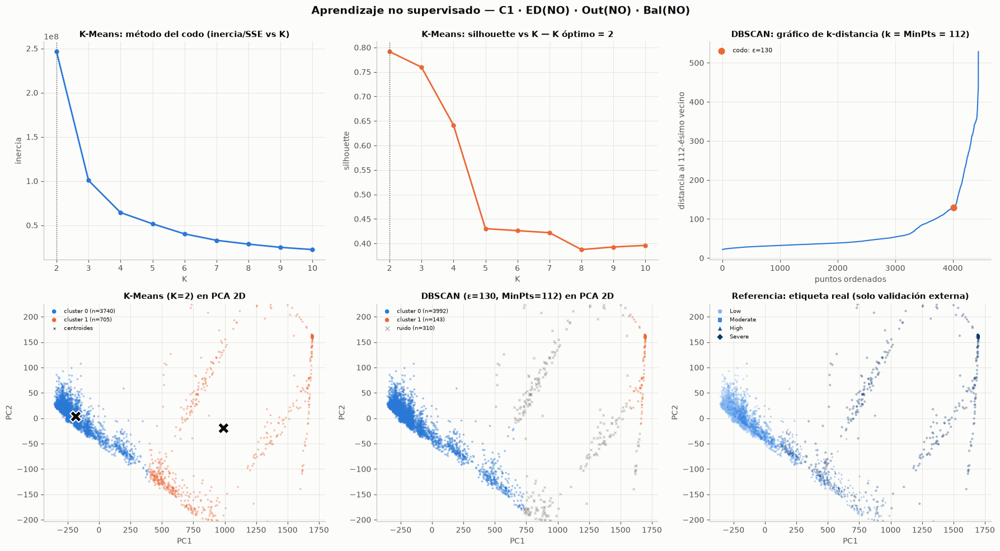

Tiempo del caso: 6.3 s
C2 · ED(NO) · Out(NO) · Bal(SI) — (12444, 56)


K-Means → K óptimo=3 (codo de inercia en K=4) | inercia=4.929e+08 | silhouette=0.6470 | tamaños=[1880, 7318, 3246]


K,2,3,4,5,6,7,8,9,10
inercia,1.347571e+09,4.928750e+08,3.039003e+08,2.235242e+08,1.727477e+08,1.413504e+08,1.173643e+08,1.012283e+08,9.009451e+07
silhouette,6.404000e-01,6.514000e-01,5.795000e-01,5.580000e-01,5.460000e-01,5.058000e-01,5.190000e-01,5.265000e-01,4.679000e-01


DBSCAN → MinPts=112 | ε codo=105.7 | ε usado=105.7 (codo) | clusters=3 | ruido=1.50 % | silhouette (sin ruido)=0.5517


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,31.7209,42.2946,52.8682,63.4419,79.3024,105.7365,132.1706,158.6047
clusters,5.0000,6.0000,4.0000,5.0000,5.0000,3.0000,2.0000,1.0000
%ruido,54.1466,36.7727,25.3214,16.4577,8.0842,1.5027,0.5947,0.0884
silhouette,0.5406,0.5116,0.2109,0.5849,0.4580,0.5517,0.6586,NaN


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1,2
clase,,,
Low,0,3111,0
Moderate,0,3000,111
High,0,1204,1907
Severe,1880,3,1228


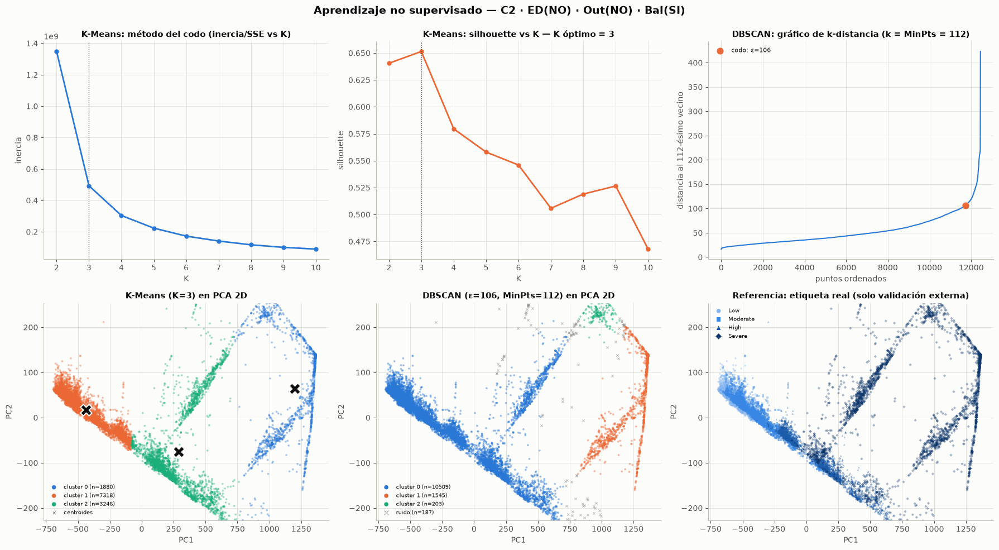

Tiempo del caso: 19.5 s
C3 · ED(NO) · Out(SI) · Bal(NO) — (4445, 56)


K-Means → K óptimo=2 (codo de inercia en K=4) | inercia=3.441e+08 | silhouette=0.7764 | tamaños=[3765, 680]


K,2,3,4,5,6,7,8,9,10
inercia,3.440669e+08,1.788099e+08,1.403144e+08,1.087898e+08,8.353604e+07,7.080001e+07,5.923139e+07,5.173381e+07,4.749367e+07
silhouette,7.757000e-01,7.346000e-01,6.280000e-01,6.325000e-01,6.212000e-01,4.108000e-01,4.060000e-01,4.013000e-01,3.647000e-01


DBSCAN → MinPts=112 | ε codo=144 | ε usado=144 (codo) | clusters=2 | ruido=8.50 % | silhouette (sin ruido)=0.8558


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,43.2005,57.6006,72.0008,86.4009,108.0011,144.0015,180.0019,216.0023
clusters,1.0000,1.0000,1.0000,3.0000,2.0000,2.0000,2.0000,2.0000
%ruido,37.4578,26.9516,24.7919,16.6254,13.6783,8.5039,6.1417,4.6794
silhouette,NaN,NaN,NaN,0.6752,0.7410,0.8558,0.8296,0.8124


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1
clase,,
Low,3096,15
Moderate,434,10
High,212,233
Severe,23,422


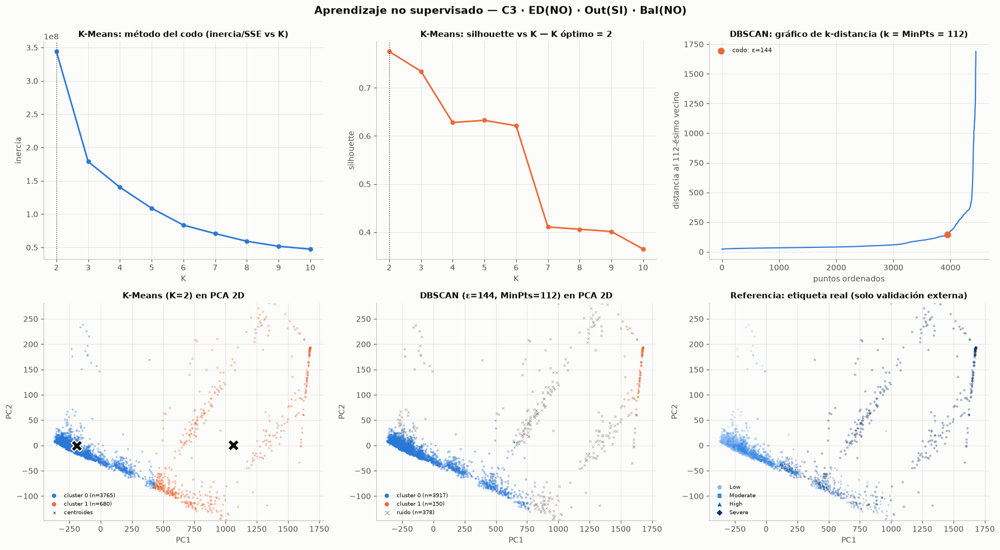

Tiempo del caso: 6.1 s
C4 · ED(NO) · Out(SI) · Bal(SI) — (12444, 56)


K-Means → K óptimo=3 (codo de inercia en K=4) | inercia=6.692e+08 | silhouette=0.6294 | tamaños=[7285, 1934, 3225]


K,2,3,4,5,6,7,8,9,10
inercia,1.550678e+09,6.691841e+08,4.816461e+08,3.982748e+08,3.176805e+08,2.664461e+08,2.351957e+08,1.956428e+08,1.708936e+08
silhouette,6.348000e-01,6.359000e-01,5.589000e-01,5.623000e-01,5.384000e-01,5.250000e-01,4.889000e-01,4.904000e-01,5.028000e-01


DBSCAN → MinPts=112 | ε codo=153.9 | ε usado=46.16 (sensibilidad (0.3× codo)) | clusters=4 | ruido=35.29 % | silhouette (sin ruido)=0.6364


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,46.1631,61.5508,76.9385,92.3262,115.4077,153.8769,192.3462,230.8154
clusters,4.0000,5.0000,4.0000,5.0000,3.0000,1.0000,1.0000,1.0000
%ruido,35.2861,21.1668,13.4201,6.1315,3.8734,2.4912,2.2420,1.9286
silhouette,0.6364,0.5874,0.4689,0.4202,0.5465,NaN,NaN,NaN


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1,2
clase,,,
Low,3095,16,0
Moderate,2988,14,109
High,1198,22,1891
Severe,4,1882,1225


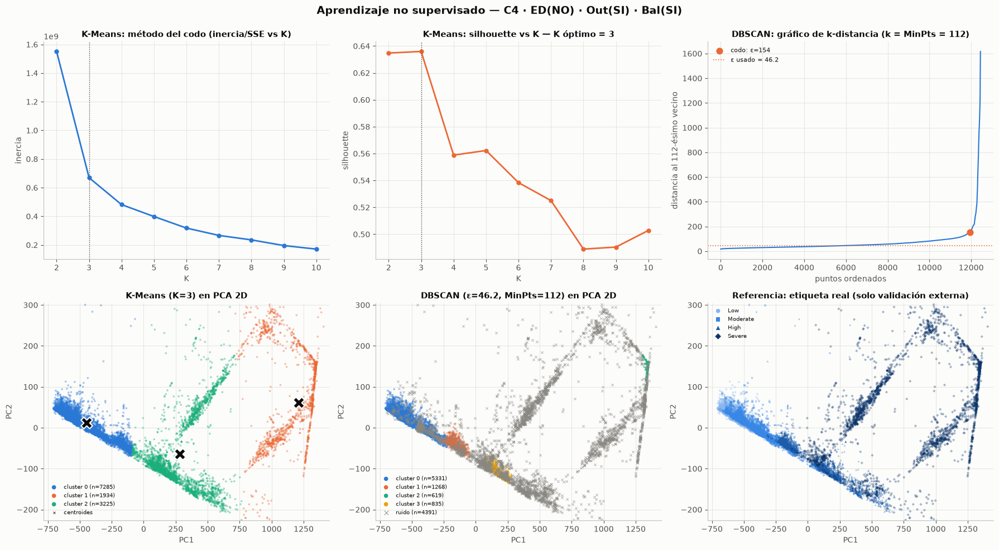

Tiempo del caso: 19.1 s
C5 · ED(SI) · Out(NO) · Bal(NO) — (4445, 56)


K-Means → K óptimo=2 (codo de inercia en K=5) | inercia=1.303e+05 | silhouette=0.4111 | tamaños=[4034, 411]


K,2,3,4,5,6,7,8,9,10
inercia,130283.842,116716.9332,110039.4244,103796.1832,100039.9653,93180.5180,91529.2312,88149.8527,86565.0332
silhouette,0.410,0.1442,0.1516,0.1583,0.1346,0.1501,0.1186,0.1207,0.1194


DBSCAN → MinPts=112 | ε codo=6.779 | ε usado=5.084 (sensibilidad (0.75× codo)) | clusters=2 | ruido=22.99 % | silhouette (sin ruido)=0.1989


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,2.0337,2.7116,3.3894,4.0673,5.0842,6.7789,8.4736,10.1683
clusters,0.0000,0.0000,1.0000,1.0000,2.0000,1.0000,1.0000,1.0000
%ruido,100.0000,100.0000,72.2610,36.4904,22.9921,4.0495,1.2823,0.1125
silhouette,NaN,NaN,NaN,NaN,0.1989,NaN,NaN,NaN


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1
clase,,
Low,3111,0
Moderate,444,0
High,412,33
Severe,67,378


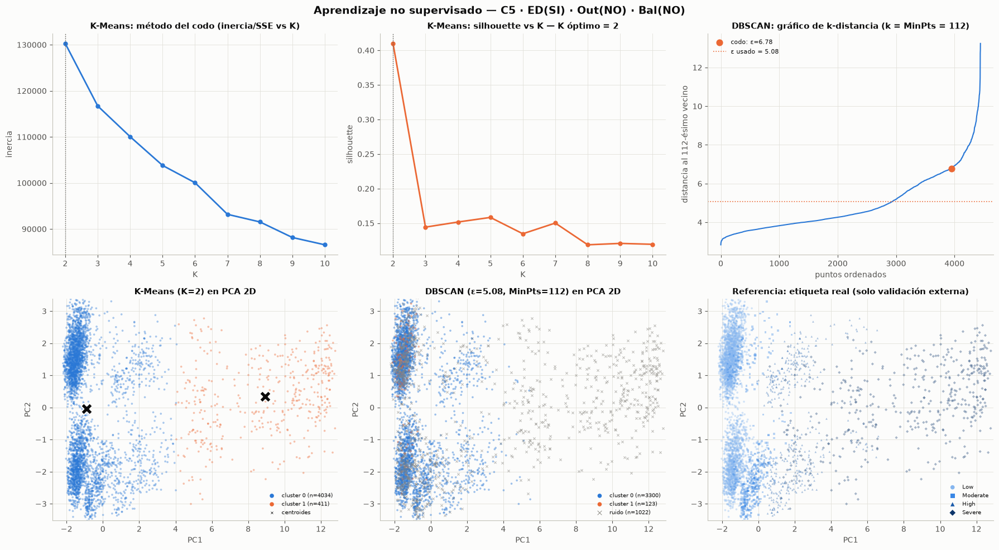

Tiempo del caso: 5.2 s
C6 · ED(SI) · Out(NO) · Bal(SI) — (12444, 56)


K-Means → K óptimo=2 (codo de inercia en K=4) | inercia=3.638e+05 | silhouette=0.2662 | tamaños=[9742, 2702]


K,2,3,4,5,6,7,8,9,10
inercia,363842.6098,326148.6602,304201.2698,290272.1415,274608.1358,263696.1654,260062.2355,246001.6419,235437.4584
silhouette,0.2638,0.1797,0.1793,0.1726,0.1863,0.1464,0.1406,0.1550,0.1607


DBSCAN → MinPts=112 | ε codo=5.317 | ε usado=5.317 (codo) | clusters=2 | ruido=5.17 % | silhouette (sin ruido)=0.2834


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,1.5951,2.1268,2.6585,3.1902,3.9878,5.3171,6.6463,7.9756
clusters,0.0000,1.0000,6.0000,7.0000,2.0000,2.0000,3.0000,2.0000
%ruido,100.0000,97.9669,80.0305,47.6776,15.7506,5.1671,2.8126,2.4429
silhouette,NaN,NaN,0.2481,0.0606,0.2151,0.2834,0.2951,0.3261


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1
clase,,
Low,3111,0
Moderate,3111,0
High,2930,181
Severe,590,2521


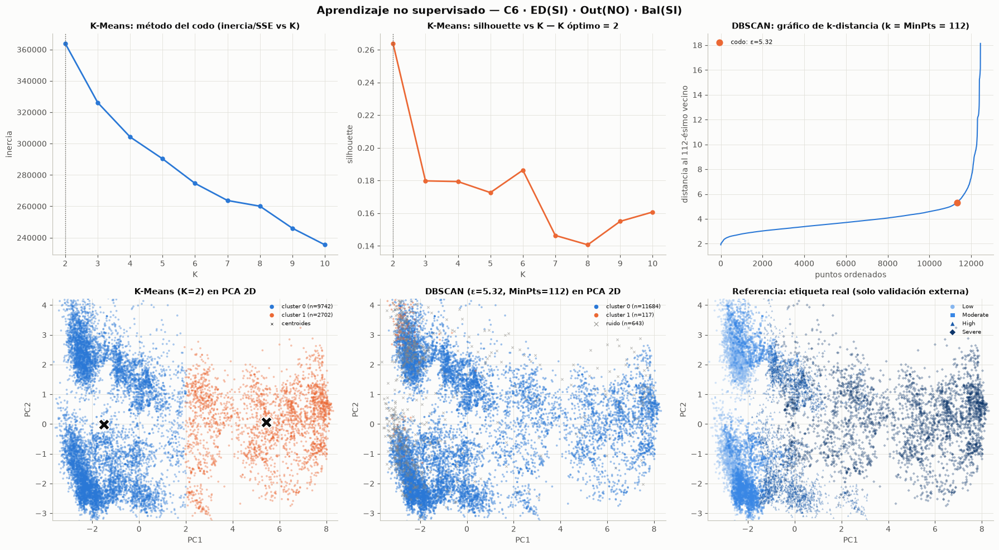

Tiempo del caso: 21.8 s
C7 · ED(SI) · Out(SI) · Bal(NO) — (4445, 56)


K-Means → K óptimo=2 (codo de inercia en K=4) | inercia=1.349e+05 | silhouette=0.3798 | tamaños=[4027, 418]


K,2,3,4,5,6,7,8,9,10
inercia,134924.1926,121905.7614,115200.8958,110365.3771,106782.8043,101265.3224,98175.0588,94600.1805,92999.8656
silhouette,0.3777,0.1354,0.1430,0.1357,0.1084,0.1461,0.1120,0.1125,0.0998


DBSCAN → MinPts=112 | ε codo=6.925 | ε usado=5.193 (sensibilidad (0.75× codo)) | clusters=2 | ruido=23.62 % | silhouette (sin ruido)=0.1996


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,2.0774,2.7699,3.4623,4.1548,5.1935,6.9247,8.6558,10.3870
clusters,0.0000,0.0000,1.0000,1.0000,2.0000,1.0000,1.0000,1.0000
%ruido,100.0000,100.0000,69.1789,36.6479,23.6220,5.2193,1.4848,0.0675
silhouette,NaN,NaN,NaN,NaN,0.1996,NaN,NaN,NaN


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1
clase,,
Low,3111,0
Moderate,444,0
High,404,41
Severe,68,377


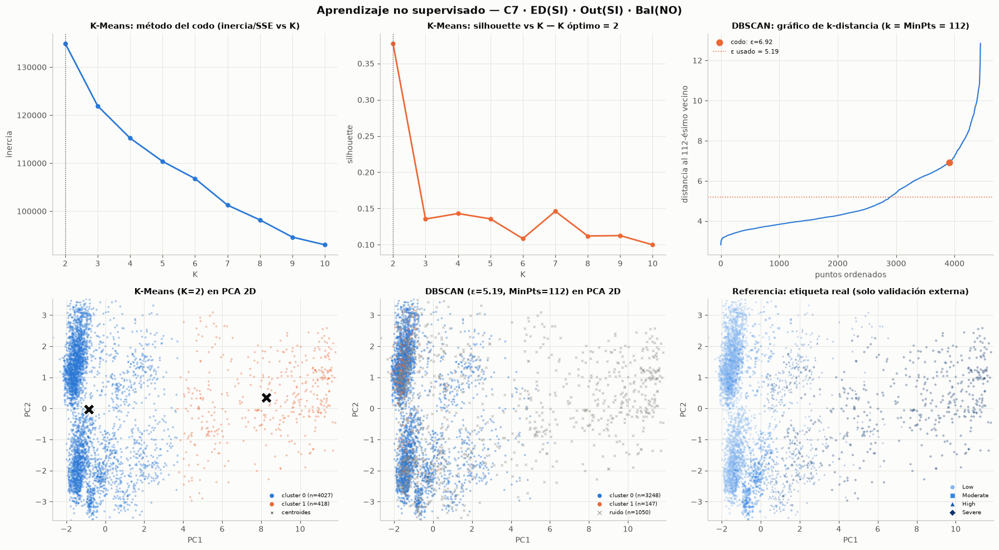

Tiempo del caso: 5.2 s
C8 · ED(SI) · Out(SI) · Bal(SI) — (12444, 56)


K-Means → K óptimo=2 (codo de inercia en K=4) | inercia=3.707e+05 | silhouette=0.2522 | tamaños=[9741, 2703]


K,2,3,4,5,6,7,8,9,10
inercia,370732.2996,334640.5495,314362.1385,301604.0272,289451.7173,274447.6998,269982.8631,255436.1624,250369.0197
silhouette,0.2499,0.1717,0.1697,0.1483,0.1471,0.1598,0.1307,0.1610,0.1562


DBSCAN → MinPts=112 | ε codo=5.379 | ε usado=5.379 (codo) | clusters=2 | ruido=6.93 % | silhouette (sin ruido)=0.2870


factor,0.30,0.40,0.50,0.60,0.75,1.00,1.25,1.50
eps,1.6137,2.1515,2.6894,3.2273,4.0341,5.3789,6.7236,8.0683
clusters,0.0000,1.0000,5.0000,7.0000,2.0000,2.0000,3.0000,2.0000
%ruido,100.0000,97.9026,79.1305,48.1999,17.7113,6.9270,2.9653,2.4269
silhouette,NaN,NaN,0.2365,0.0596,0.1946,0.2870,0.2954,0.3289


Tabla de contingencia K-Means (filas = clase real, columnas = cluster):


cluster,0,1
clase,,
Low,3111,0
Moderate,3111,0
High,2913,198
Severe,606,2505


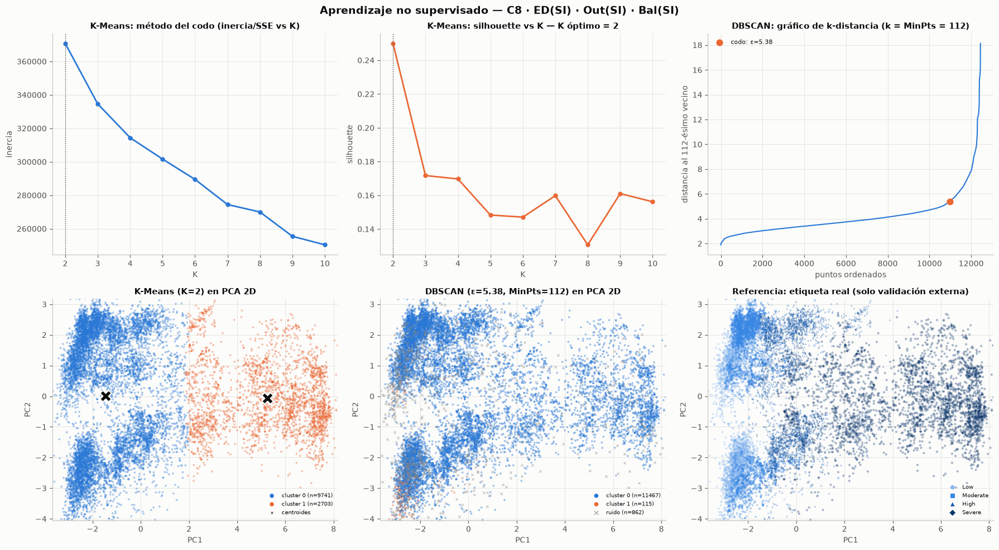

Tiempo del caso: 23.4 s


In [35]:
resultados_ns, sensibilidad_db, asignaciones_3, modelos_ns = [], [], [], {}
for num, d in datos_casos.items():
    t0 = time.time()
    X = d["X_train"]
    print("=" * 100, f"\n{d['etiqueta']} — {X.shape}")

    # --- K-Means ---
    barrido = barrido_kmeans(X)
    k_opt = int(barrido.loc[barrido.silhouette.idxmax(), "K"])
    km = KMeans(n_clusters=k_opt, init="k-means++", n_init=10, random_state=SEMILLA).fit(X)
    sil_km = silhouette_score(X, km.labels_)
    tamanos = np.bincount(km.labels_)
    print(f"K-Means → K óptimo={k_opt} (codo de inercia en K={barrido.K[codo(barrido.inercia)]}) | "
          f"inercia={km.inertia_:.4g} | silhouette={sil_km:.4f} | tamaños={tamanos.tolist()}")
    display(barrido.round(4).set_index("K").T)

    # --- DBSCAN ---
    min_pts = 2 * X.shape[1]
    kdist = k_distancias(X, min_pts)
    i_codo = codo(kdist)
    eps_codo = float(kdist[i_codo])
    db, n_cl, ruido, sil_db = evaluar_dbscan(X, eps_codo, min_pts)
    sens = []
    for f in (0.3, 0.4, 0.5, 0.6, 0.75, 1.0, 1.25, 1.5):
        m_, n_, r_, s_ = evaluar_dbscan(X, f * eps_codo, min_pts)
        sens.append({"caso": num, "factor": f, "eps": f * eps_codo, "clusters": n_, "%ruido": r_, "silhouette": s_})
        sensibilidad_db.append(sens[-1])
    sens = pd.DataFrame(sens)
    eps_usado, criterio_eps = eps_codo, "codo"
    if n_cl < 2:
        validos = sens[(sens.clusters >= 2) & (sens["%ruido"] <= 50)]
        if len(validos):
            mejor = validos.loc[validos.silhouette.idxmax()]
            eps_usado, criterio_eps = float(mejor.eps), f"sensibilidad ({mejor.factor}× codo)"
            db, n_cl, ruido, sil_db = evaluar_dbscan(X, eps_usado, min_pts)
    print(f"DBSCAN → MinPts={min_pts} | ε codo={eps_codo:.4g} | ε usado={eps_usado:.4g} ({criterio_eps}) | "
          f"clusters={n_cl} | ruido={ruido:.2f} % | silhouette (sin ruido)={sil_db:.4f}")
    display(sens.drop(columns="caso").round(4).set_index("factor").T)

    # --- validación externa (etiqueta real, solo para evaluar) ---
    y_tr = d["y_train"].values
    ari_km, nmi_km = adjusted_rand_score(y_tr, km.labels_), normalized_mutual_info_score(y_tr, km.labels_)
    ari_db, nmi_db = adjusted_rand_score(y_tr, db.labels_), normalized_mutual_info_score(y_tr, db.labels_)
    print("Tabla de contingencia K-Means (filas = clase real, columnas = cluster):")
    display(pd.crosstab(pd.Categorical(y_tr, CLASES), km.labels_, rownames=["clase"], colnames=["cluster"]))

    # --- tres registros de prueba ---
    X3 = d["X_test"][IDX_PRUEBA_3]
    for j, idx in enumerate(IDX_PRUEBA_3):
        asignaciones_3.append({"caso": num, "registro_prueba": idx, "real": y_test[idx],
                               "cluster_kmeans": int(km.predict(X3)[j]),
                               "cluster_dbscan": int(asignar_dbscan(db, X, X3)[j])})

    resultados_ns.append({"caso": num, "ED": "SI" if d["escalado"] else "NO", "OUTLIERS": "SI" if d["outliers"] else "NO",
                          "BALANCEO": "SI" if d["balanceo"] else "NO", "K_optimo": k_opt, "km_inercia": km.inertia_,
                          "km_silhouette": sil_km, "km_tamanos": tamanos.tolist(), "km_ARI": ari_km, "km_NMI": nmi_km,
                          "db_minpts": min_pts, "db_eps_codo": eps_codo, "db_eps": eps_usado, "db_criterio_eps": criterio_eps,
                          "db_clusters": n_cl, "db_%ruido": ruido, "db_silhouette": sil_db, "db_ARI": ari_db, "db_NMI": nmi_db})
    modelos_ns[num] = {"kmeans": km, "dbscan": db}
    graficar_no_supervisado(d, barrido, k_opt, km, kdist, i_codo, eps_usado, min_pts, db, num)
    print(f"Tiempo del caso: {time.time() - t0:.1f} s")

resultados_ns = pd.DataFrame(resultados_ns).set_index("caso")
sensibilidad_db = pd.DataFrame(sensibilidad_db)
asignaciones_3 = pd.DataFrame(asignaciones_3)

## 19. Tabla de la figura 3

In [36]:
figura3 = resultados_ns[["ED", "OUTLIERS", "BALANCEO", "km_inercia", "km_silhouette", "db_silhouette"]].rename(
    columns={"km_inercia": "K-MEANS INERTIA", "km_silhouette": "K-MEANS SILHOUETTE", "db_silhouette": "DBSCAN SILHOUETTE"})
display(figura3.round(4))
guardar_tabla(figura3.round(4), "figura3_no_supervisado")
detalle_ns = resultados_ns.drop(columns=["ED", "OUTLIERS", "BALANCEO"])
display(detalle_ns.round(4))
guardar_tabla(detalle_ns.round(4), "detalle_no_supervisado")
guardar_tabla(sensibilidad_db.round(4), "sensibilidad_dbscan")
display(asignaciones_3.set_index(["caso", "registro_prueba"]))
guardar_tabla(asignaciones_3, "asignaciones_3_registros_no_supervisado")

,ED,OUTLIERS,BALANCEO,K-MEANS INERTIA,K-MEANS SILHOUETTE,DBSCAN SILHOUETTE
caso,,,,,,
1,NO,NO,NO,2.464625e+08,0.7917,0.8643
2,NO,NO,SI,4.928750e+08,0.6470,0.5517
3,NO,SI,NO,3.440669e+08,0.7764,0.8558
4,NO,SI,SI,6.691841e+08,0.6294,0.6364
5,SI,NO,NO,1.302838e+05,0.4111,0.1989
6,SI,NO,SI,3.638426e+05,0.2662,0.2834
7,SI,SI,NO,1.349242e+05,0.3798,0.1996
8,SI,SI,SI,3.707323e+05,0.2522,0.2870


,K_optimo,km_inercia,km_silhouette,km_tamanos,km_ARI,km_NMI,db_minpts,db_eps_codo,db_eps,db_criterio_eps,db_clusters,db_%ruido,db_silhouette,db_ARI,db_NMI
caso,,,,,,,,,,,,,,,
1,2,2.464625e+08,0.7917,"[3740, 705]",0.5412,0.4999,112,129.7920,129.7920,codo,2,6.9741,0.8643,0.3669,0.3887
2,3,4.928750e+08,0.6470,"[1880, 7318, 3246]",0.3284,0.4913,112,105.7365,105.7365,codo,3,1.5027,0.5517,0.0976,0.2766
3,2,3.440669e+08,0.7764,"[3765, 680]",0.5040,0.4473,112,144.0015,144.0015,codo,2,8.5039,0.8558,0.3225,0.3008
4,3,6.691841e+08,0.6294,"[7285, 1934, 3225]",0.3254,0.4732,112,153.8769,46.1631,sensibilidad (0.3× codo),4,35.2861,0.6364,0.3692,0.4971
5,2,1.302838e+05,0.4111,"[4034, 411]",0.3422,0.3833,112,6.7789,5.0842,sensibilidad (0.75× codo),2,22.9921,0.1989,0.2058,0.1472
6,2,3.638426e+05,0.2662,"[9742, 2702]",0.2032,0.3627,112,5.3171,5.3171,codo,2,5.1671,0.2834,0.0038,0.0335
7,2,1.349242e+05,0.3798,"[4027, 418]",0.3463,0.3804,112,6.9247,5.1935,sensibilidad (0.75× codo),2,23.6220,0.1996,0.1702,0.1179
8,2,3.707323e+05,0.2522,"[9741, 2703]",0.1998,0.3570,112,5.3789,5.3789,codo,2,6.9270,0.2870,0.0041,0.0290


real  cluster_kmeans  cluster_dbscan
caso registro_prueba                                        
1    556                 Low               0               0
     427                High               1               0
     385              Severe               1              -1
2    556                 Low               1               0
     427                High               2               0
     385              Severe               0              -1
3    556                 Low               0               0
     427                High               1               0
     385              Severe               1              -1
4    556                 Low               0               0
     427                High               2              -1
     385              Severe               1              -1
5    556                 Low               0               0
     427                High               0               0
     385              Severe               1              -1
6    556                 Low               0               0
     427                High               0               0
     385              Severe               1              -1
7    556                 Low               0               0
     427                High               0               0
     385              Severe               1              -1
8    556                 Low               0               0
     427                High               0               0
     385              Severe               1              -1

## 20. Silhouette por caso — K-Means y DBSCAN

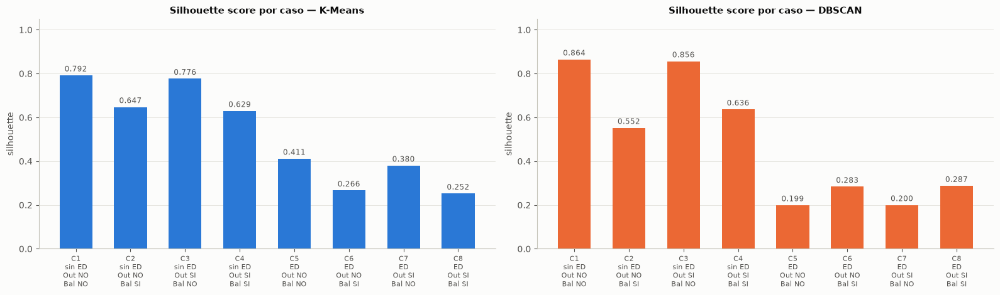

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, col, nombre, color in ((axes[0], "km_silhouette", "K-Means", COLOR_PAR[0]),
                               (axes[1], "db_silhouette", "DBSCAN", COLOR_PAR[1])):
    vals = resultados_ns[col]
    etiquetas = [f"C{n}\n{'ED' if r.ED == 'SI' else 'sin ED'}\nOut {r.OUTLIERS}\nBal {r.BALANCEO}"
                 for n, r in resultados_ns.iterrows()]
    barras = ax.bar(range(8), vals.fillna(0).values, color=color, width=0.6)
    for b, v in zip(barras, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, max(b.get_height(), 0) + 0.01,
                "N/D" if np.isnan(v) else f"{v:.3f}", ha="center", va="bottom", fontsize=8.5, color=TINTA2)
    ax.set_xticks(range(8), etiquetas, fontsize=8)
    ax.set_ylim(min(0, np.nanmin(vals.values) - 0.05), 1.05)
    ax.axhline(0, color="#c3c2b7", linewidth=1)
    ax.set_title(f"Silhouette score por caso — {nombre}"); ax.set_ylabel("silhouette")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar_figura(fig, "nosup_silhouette_casos")

## 21. Interpretación de los clusters en el dominio (perfil de variables originales)
Se describen los clusters de K-Means de los casos 5 y 8 (con escalado) con las medias de las variables de
tráfico en su **escala original**. El objetivo es ver si los grupos tienen sentido para la movilidad
urbana: tráfico fluido frente a congestionado, hora punta, tipo de vía.

In [38]:
VARS_PERFIL = ["vehicle_count", "average_speed", "traffic_density", "queue_length", "average_wait_time",
               "heavy_vehicle_count", "hour", "rush_hour", "lanes", "parking_occupancy"]
perfiles = {}
for num in (5, 8):
    d, km = datos_casos[num], modelos_ns[num]["kmeans"]
    perfil = d["X_train_df"][VARS_PERFIL].assign(cluster=km.labels_).groupby("cluster").mean()
    perfil["n"] = np.bincount(km.labels_)
    perfil["road_type_mas_comun"] = d["X_train_df"].assign(cluster=km.labels_).groupby("cluster").road_type.agg(
        lambda s: s.value_counts().index[0])
    perfil["clase_real_mayoritaria"] = pd.Series(d["y_train"].values).groupby(km.labels_).agg(
        lambda s: f"{s.value_counts().index[0]} ({100 * s.value_counts().iloc[0] / len(s):.0f} %)")
    perfiles[num] = perfil
    print(f"Perfil de clusters K-Means — {d['etiqueta']}")
    display(perfil.round(2))
    guardar_tabla(perfil.round(3), f"perfil_clusters_caso{num}")

    db = modelos_ns[num]["dbscan"]
    perfil_db = d["X_train_df"][VARS_PERFIL].assign(cluster=db.labels_).groupby("cluster").mean()
    perfil_db["n"] = pd.Series(db.labels_).value_counts().sort_index().values
    perfil_db["clase_real_mayoritaria"] = pd.Series(d["y_train"].values).groupby(db.labels_).agg(
        lambda s: f"{s.value_counts().index[0]} ({100 * s.value_counts().iloc[0] / len(s):.0f} %)")
    print(f"Perfil de clusters DBSCAN (−1 = ruido) — {d['etiqueta']}")
    display(perfil_db.round(2))
    guardar_tabla(perfil_db.round(3), f"perfil_dbscan_caso{num}")

Perfil de clusters K-Means — C5 · ED(SI) · Out(NO) · Bal(NO)


,vehicle_count,average_speed,traffic_density,queue_length,average_wait_time,heavy_vehicle_count,hour,rush_hour,lanes,parking_occupancy,n,road_type_mas_comun,clase_real_mayoritaria
cluster,,,,,,,,,,,,,
0,275.58,52.83,34.16,15.49,1.54,13.27,11.16,0.17,2.73,40.99,4034,Arterial,Low (77 %)
1,1575.60,24.64,189.03,263.04,26.16,76.67,11.84,0.34,2.94,41.49,411,Arterial,Severe (92 %)


Perfil de clusters DBSCAN (−1 = ruido) — C5 · ED(SI) · Out(NO) · Bal(NO)


,vehicle_count,average_speed,traffic_density,queue_length,average_wait_time,heavy_vehicle_count,hour,rush_hour,lanes,parking_occupancy,n,clase_real_mayoritaria
cluster,,,,,,,,,,,,
-1,804.96,40.30,96.95,114.69,11.40,38.92,12.13,0.25,2.80,38.69,1022,Low (40 %)
0,277.11,53.20,34.45,15.62,1.56,13.40,11.12,0.17,2.73,41.30,3300,Low (78 %)
1,179.99,52.74,22.14,14.99,1.51,8.59,6.51,0.01,2.69,53.38,123,Low (99 %)


Perfil de clusters K-Means — C8 · ED(SI) · Out(SI) · Bal(SI)


,vehicle_count,average_speed,traffic_density,queue_length,average_wait_time,heavy_vehicle_count,hour,rush_hour,lanes,parking_occupancy,n,road_type_mas_comun,clase_real_mayoritaria
cluster,,,,,,,,,,,,,
0,478.46,48.75,60.87,20.95,2.21,23.46,12.66,0.44,2.66,35.27,9741,Arterial,Moderate (32 %)
1,1612.37,24.83,192.50,272.14,26.99,79.59,11.82,0.28,2.96,41.42,2703,Arterial,Severe (93 %)


Perfil de clusters DBSCAN (−1 = ruido) — C8 · ED(SI) · Out(SI) · Bal(SI)


,vehicle_count,average_speed,traffic_density,queue_length,average_wait_time,heavy_vehicle_count,hour,rush_hour,lanes,parking_occupancy,n,clase_real_mayoritaria
cluster,,,,,,,,,,,,
-1,582.34,51.57,69.29,76.15,8.14,29.41,12.05,0.26,2.73,37.63,862,Low (52 %)
0,740.69,42.86,91.62,76.07,7.62,36.38,12.57,0.42,2.72,36.35,11467,High (26 %)
1,203.83,52.65,25.10,14.69,1.48,9.50,5.65,0.04,2.70,54.61,115,Low (94 %)


## 22. Resumen final
Las tablas de las figuras 1 y 3 y todas las gráficas quedaron guardadas en `resultados/`. El análisis de
resultados y las conclusiones están en el documento de diseño (PDF).

In [39]:
print("Mejor F1 por algoritmo:")
display(resultados_sup.loc[resultados_sup.groupby("algoritmo").f1.idxmax(), ["algoritmo", "caso", "accuracy", "f1"]]
        .set_index("algoritmo").round(4))
print("Archivos generados:", len(os.listdir(DIR_FIG)), "figuras,", len(os.listdir(DIR_TAB)), "tablas")

Mejor F1 por algoritmo:


,caso,accuracy,f1
algoritmo,,,
KNN,3,0.9622,0.9330
Red neuronal,1,0.9748,0.9555
SVM,1,0.9801,0.9624
Árbol de decisión,1,0.9780,0.9602


Archivos generados: 38 figuras, 24 tablas
